# Forecasting where coding bans send a model: demo

**Artifact** `art_1AYTO1Epb_7t` (iteration 3, experiment 13) · **model studied** Qwen3-8B (bf16, revision `b968826d`, thinking off) · **tasks** the 12 frozen coding tasks of exp11

Tell a code model *"Do not use a full sort for this task."* and it has to write something else. **Where does it go, and can that be predicted without ever showing the model the ban?**

Before sampling a single ban, the experiment built four *ban-free* forecasts of each task's landing and hash-sealed them (`commitments.log`, `SEAL_BEFORE_BANS`):

| family | how it forecasts the landing without the ban text |
|---|---|
| **SUBTRACT** | veto the tokens of the default program's distinctive n-gram (vLLM `logit_bias`), one-shot, persistent and over 3 iterated rounds, and see where the model goes |
| **LADDER** | generic pushes: a nonce ban ("the Zorblax method"), a novelty instruction, and 3 matched-norm random directions patched into the task-spec states at layers 12–23 |
| **ASSOCIATE** | the model's own answer to "what is the standard alternative to X for this task?" |
| **PROXIMITY** | the algorithm whose programs are closest to the default's (AST Zhang–Shasha tree-edit distance) |

It then sampled 1,200 bans (12 tasks × 5 wordings W1–W5 × 20 samples), labelled every program with the gated exp11 labellers, and scored each family by its mean log score on where the bans landed.

**What runs here.** `method.py` is a stage runner. It launches `src/*.py` as subprocesses: five GPU stages that run Qwen3-8B (vLLM and HF sampling, plus one fp32 rescoring stage; about 45 min on an RTX 4090) and a set of CPU stages. A notebook cannot run the GPU stages in minutes, so their **stored, labelled outputs** stand in for them. `mini_demo_data.json` holds 96 of the 1,200 ban samples (8 per task, chosen to keep each task's label mix and gate outcome) together with the committed forecasts. The notebook then re-runs the CPU analysis with the original code from `src/score.py`, `src/c2b.py`, `src/template_effect.py`, `src/analyze.py` and `src/posthoc.py`:

1. rebuild the ban prompts and seeds from the frozen constants;
2. apply the frozen scoring rules and run their unit tests;
3. **C1**: which forecast family predicts the landing (frozen advance rule);
4. post-hoc: count wins by defined forecasts only, and compare every family with the uniform reference;
5. **C2b**: does a token veto land where the ban lands;
6. the wording (template) effect, and whether programs that keep the banned algorithm admit it.

Every demo number is printed next to its full-run value.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the original pipeline logs through it)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, statsmodels, matplotlib — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'statsmodels==0.14.6', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# method.py
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# src/common.py
import hashlib
import json
import math
import os
from typing import Any, Iterable

# src/score.py, src/c2b.py, src/template_effect.py, src/analyze.py, src/posthoc.py
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd

# notebook additions: tables, figures, a namespace for the template_effect module
import types

import matplotlib.pyplot as plt
from IPython.display import display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-3/experiment-13/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
examples = data["datasets"][0]["examples"]
print(data["metadata"]["description"])
print(f"dataset '{data['datasets'][0]['dataset']}': {len(examples)} examples "
      f"(full run: {data['metadata']['n_ban_samples_full_run']})")
print("fields:", list(examples[0]))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Curated demo subset of art_1AYTO1Epb_7t ('Forecasting where coding bans send a model', Qwen3-8B bf16): 96 of the 1,200 labelled modal-ban samples (8 per task) plus the committed ban-free forecasts and the full-run results for comparison.
dataset 'modal_ban_samples': 96 examples (full run: 1200)
fields: ['input', 'output', 'predict_subtract', 'predict_ladder', 'predict_associate', 'predict_proximity', 'metadata_task', 'metadata_arm', 'metadata_arm_description', 'metadata_template', 'metadata_sample_id', 'metadata_seed', 'metadata_banned_default', 'metadata_label', 'metadata_passed', 'metadata_labeller_source', 'metadata_engine', 'metadata_finish_reason', 'metadata_n_tokens', 'metadata_code']


## Configuration

The demo's tunable parameters. With the values shipped below, the notebook uses all 96 curated samples and the original replicate counts, and it runs in well under a minute after the install cell.

- `N_BAN_PER_TASK`: ban samples analysed per task. The mini data holds 8 per task; the full run had 100.
- `GATE_MIN_NON_BANNED`: the frozen gate asks for ≥ 20 non-banned attempts out of 100 samples. This value scales that to the subset (8 → 2). The other half of the gate, avoidance ≥ 0.5, is unchanged.
- `POSTHOC_BOOTSTRAP`: task-cluster bootstrap replicates for the post-hoc confidence intervals.
- `C2B_NULL_REPLICATES`: replicates of the C2b template-resampling null.

In [5]:
# Ban samples analysed per task (the mini data holds 8 per task; the full run had 100 per task, 1,200 in all)
N_BAN_PER_TASK = 8
# Frozen gate: >= 20 non-banned attempts out of 100 samples per task; scaled to the demo subset (8 per task -> 2)
GATE_MIN_NON_BANNED = max(1, math.ceil(20 * N_BAN_PER_TASK / 100))
# Task-cluster bootstrap replicates of the post-hoc CIs (original: 2000)
POSTHOC_BOOTSTRAP = 2000
# Replicates of the C2b template-resampling null (original frozen value: 2000)
C2B_NULL_REPLICATES = 2000

## 1. The pipeline: `method.py`

`method.py` runs the study stage by stage, and each GPU stage gets its own process so that GPU memory is released when it exits. The `commit` stage seals the hash chain before `gen_c` samples any ban, and `gen_c` refuses to run without a valid `SEAL_BEFORE_BANS` line.

The cell below holds `method.py` unchanged except for `ROOT`, which in the original is derived from `__file__`. It prints the stage list that `main()` shows as help. Nothing is launched here: the stage scripts are not part of the notebook, and the five stages marked GPU need Qwen3-8B on a 24 GB GPU. Their labelled outputs come from the data instead, and the CPU stages `analyze` and `posthoc` are re-run inline further down.

In [6]:
METHOD_DOC = """Predicting where coding bans send a model (iteration 3): entry point.

Runs the pipeline stage by stage.  Every GPU stage is a separate Python process so GPU memory is released at exit
(A: vLLM ban-free arms; B: HF norms + random directions; C: vLLM modal bans; D: HF band-patch control; D2: HF fp32
FRLP rescoring).  No modal-ban prompt is sampled before the 'commit' stage seals the hash chain; stage C refuses to
run without a valid SEAL_BEFORE_BANS line.

    .venv/bin/python method.py all            # the full pipeline, in order
    .venv/bin/python method.py <stage> ...    # one or more stages (see STAGES)
"""

ROOT = Path.cwd()  # original: Path(__file__).resolve().parent, the repository root
PY = sys.executable
SRC = ROOT / "src"

# stage -> (script relative to the repo, arguments, what it does)
STAGES: dict[str, tuple[str, list[str], str]] = {
    "setup": ("src/setup_inputs.py", [], "S0.1-0.2 copy + verify the frozen bench, provenance commit, env.json"),
    "recheck": ("src/labelpool.py", [], "S0.3 labeller re-check on gold sets and references vs gate.json"),
    "prompts": ("src/prompts.py", [], "S0.4 ban / twin / nonce / novelty prompts, token alignment, spec spans"),
    "ngrams": ("src/ngrams.py", [], "S0.5 distinctive + sham n-grams (FP8 pilot), unit tests"),
    "proximity": ("src/proximity.py", [], "S0.6 AST tree-edit-distance PROXIMITY nominees"),
    "nominees": ("src/forecasts.py", ["nominees"], "S0.7-0.8 ASSOCIATE and FRLP_FP8 nominees"),
    "gen_a": ("src/vllm_stage.py", ["A"], "S1 GPU process A: twin, vetoes, nonce, novelty, iterated rounds"),
    "hf_b": ("src/hf_stage.py", ["B"], "S1.7 GPU process B: norms, random directions, HF twin control"),
    "forecasts": ("src/forecasts.py", ["build"], "S1d ban-free forecasts"),
    "commit": ("src/forecasts.py", ["commit"], "S1d hash-chained commitment + SEAL_BEFORE_BANS"),
    "gen_c": ("src/vllm_stage.py", ["C"], "S2 GPU process C: modal bans (guarded)"),
    "hf_d": ("src/hf_stage.py", ["D"], "S2b(i) GPU process D: band-patch positive control"),
    "frlp": ("src/frlp_rescore.py", [], "S2b(ii) fp32 FRLP rescoring (descriptive)"),
    "analyze": ("src/analyze.py", [], "S3 committed analysis: C1, C2b, descriptives, template effect, figures"),
    "posthoc": ("src/posthoc.py", [], "post-hoc (not pre-registered) sensitivity analyses"),
    "sanity": ("src/sanity.py", [], "T9 post-run sanity checks"),
    "figures": ("src/figures_extra.py", [], "extra figures (redrawn log-score plot, forecast table)"),
    "outputs": ("src/outputs.py", [], "data/samples.jsonl + method_out.json"),
    "audit": ("audit/rederive.py", [], "independent re-derivation + placebos"),
}
ORDER = ["setup", "recheck", "prompts", "ngrams", "proximity", "nominees", "gen_a", "hf_b", "forecasts", "commit",
         "gen_c", "hf_d", "frlp", "analyze", "posthoc", "sanity", "figures", "outputs", "audit"]


def run_stage(name: str) -> None:
    script, args, what = STAGES[name]
    cwd = ROOT / Path(script).parent
    logger.info(f"=== stage {name}: {what}")
    t0 = time.time()
    r = subprocess.run([PY, str(ROOT / script), *args], cwd=cwd)
    if r.returncode != 0:
        raise SystemExit(f"stage {name} failed with exit code {r.returncode}")
    logger.info(f"=== stage {name} done in {time.time() - t0:.0f}s")


@logger.catch(reraise=True)
def main() -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    (ROOT / "logs").mkdir(exist_ok=True)
    logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")
    names = sys.argv[1:] or ["--help"]
    if names[0] in ("-h", "--help"):
        print(METHOD_DOC)  # original: print(__doc__)
        for n in ORDER:
            print(f"  {n:<10} {STAGES[n][2]}")
        return
    if names == ["all"]:
        names = ORDER
    for n in names:
        if n not in STAGES:
            raise SystemExit(f"unknown stage {n!r}; choose from {', '.join(ORDER)} or 'all'")
        run_stage(n)


# Notebook: main() is not called (inside a kernel, sys.argv holds the kernel's own arguments).  Below is its help
# output; the stages marked [GPU] are replaced by the stored labelled samples, 'analyze' + 'posthoc' run further down.
GPU_STAGES = {"gen_a", "hf_b", "gen_c", "hf_d", "frlp"}
print(METHOD_DOC)
for n in ORDER:
    print(f"  {n:<10} {STAGES[n][2]}" + ("   [GPU]" if n in GPU_STAGES else ""))

Predicting where coding bans send a model (iteration 3): entry point.

Runs the pipeline stage by stage.  Every GPU stage is a separate Python process so GPU memory is released at exit
(A: vLLM ban-free arms; B: HF norms + random directions; C: vLLM modal bans; D: HF band-patch control; D2: HF fp32
FRLP rescoring).  No modal-ban prompt is sampled before the 'commit' stage seals the hash chain; stage C refuses to
run without a valid SEAL_BEFORE_BANS line.

    .venv/bin/python method.py all            # the full pipeline, in order
    .venv/bin/python method.py <stage> ...    # one or more stages (see STAGES)

  setup      S0.1-0.2 copy + verify the frozen bench, provenance commit, env.json
  recheck    S0.3 labeller re-check on gold sets and references vs gate.json
  prompts    S0.4 ban / twin / nonce / novelty prompts, token alignment, spec spans
  ngrams     S0.5 distinctive + sham n-grams (FP8 pilot), unit tests
  proximity  S0.6 AST tree-edit-distance PROXIMITY nominees
  nominees 

## 2. Frozen constants and the task table (`src/common.py`)

These are the values every stage agrees on:

- the model and its revision;
- the 12 tasks in stage order, each with its default algorithm D (the modal label of the exp11 pilot);
- the five ban wordings W1–W5, each with a neutral twin;
- the decoding settings;
- the frozen analysis constants: gate, smoothing, advance rule and C2b.

File-I/O and GPU helpers are left out. `spec(task)` reads the task spec (catalogue of algorithms, aliases, task text) from the loaded data instead of `inputs/bench/<task>/spec.json`. The last lines apply the two demo-scale overrides from the configuration cell, printing the frozen values first.

In [7]:
MODEL_ID = "Qwen/Qwen3-8B"
REVISION = "b968826d9c46dd6066d109eabc6255188de91218"

# Stage-A order (exp11 commitments.log, stageA_order, R2 excluded by the 12-task freeze cap)
TASK_ORDER = ["T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11"]
# The default D of every task = the modal label of the exp11 FP8 pilot (protocol table); checked against pilot_rows.
DEFAULTS = {"T03": "full_sort", "T04": "naive", "T06": "hash_set", "T05": "hash_map", "T10": "union_find",
            "R1": "greedy_end", "T08": "iteration", "R3": "kahn", "T13": "sort_sweep", "R6": "binary_search",
            "T14": "sort_by_count", "T11": "quadratic_dp"}

WS = ["W1", "W2", "W3", "W4", "W5"]
# W1-W5 (ban, neutral) verbatim from the shared protocol (exp7 src/config.py, exp8 cfg.py).
TEMPLATES = {
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
NONCE_X = "the Zorblax method"
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
FILLER = " ."
NOUN_EXCLUSIONS = {"ass", "bucket", "chain", "edge", "game", "graph", "grid", "head", "heap", "key", "line", "link",
                   "list", "map", "maze", "net", "node", "path", "point", "queue", "ring", "road", "route", "search",
                   "stack", "step", "street", "table", "track", "train", "tree", "walk", "way", "web"}

MAX_NEW = 1024
DECODING = {"temperature": 1.0, "top_p": 1.0, "top_k": -1, "min_p": 0.0, "repetition_penalty": 1.0,
            "max_tokens": MAX_NEW, "thinking": False}
BAND = list(range(12, 24))  # layers 12-23 (0-indexed decoder layers); output of layer l = hidden_states[l + 1]
N_RAND_DIRS = 3
IM_END = 151645
ENDOFTEXT = 151643
EOS_IDS = (IM_END, ENDOFTEXT)
FENCE_OPEN = "```python\n"
FENCE_CLOSE = "```"
CHAT_TAIL = "<|im_start|>assistant\n<think>\n\n</think>\n\n"

# Sample sizes (plan): twin 5x10, nonce 5x10, novelty 50, random directions 3 x 50 (5x10), bans 5x20.
N_TWIN_PER_T = 10
N_NONCE_PER_T = 10
N_NOVELTY = 50
N_RAND_PER_T = 10
N_BAN_PER_T = 20
N_HF_TWIN_PER_T = 10
N_BANDPATCH_PER_T = 10

FROZEN_CONSTANTS = {
    "gate": {"min_avoidance": 0.5, "min_non_banned_attempts": 20},
    "forecast_min_non_default": 20,
    "smoothing": {"raw": 0.93, "uniform_survivors": 0.05, "other": 0.02},
    "advance": {"margin_nats": 0.10, "min_wins": 3},
    "wilcoxon_min_events": 10,
    "c2b": {"min_one_shot_avoidance": 0.5, "min_attempts_in_S_prime": 10, "confirm_share": 2 / 3,
            "elsewhere_share": 1 / 3, "null_replicates": 2000, "null_seed": 20261021, "null_quantile": 0.95,
            "min_eligible_events": 3},
    "iterated": {"trigger_default_share": 0.20, "max_rounds": 3, "coverage": 0.8, "max_greedy_ngrams": 3},
    "ngram": {"n_max": 6, "coverage": 0.8, "co_veto_collateral": 0.5},
    "veto_cap": 32,
    "ladder_exists_min_pushes": 2,
    "unaimed_share": 0.5,
    "tie_rules": "top-1: argmax over S of p_raw, ties to catalogue order (flagged); n-gram: min max-collateral, then "
                 "smaller n, higher coverage, lexicographically smallest id tuple",
}


def setup_logging(name: str) -> None:
    # original: also a rotating file sink logs/<name>.log
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def stable_seed(*parts: Any) -> int:
    """Per-request seed = int(sha256('iter3|exp|task|arm|template|idx')[:8], 16)."""
    key = "iter3|exp|" + "|".join(str(p) for p in parts)
    return int(hashlib.sha256(key.encode()).hexdigest()[:8], 16)


def spec(task: str) -> dict:
    # original: read_json(task_dir(task) / "spec.json"), the frozen bench copy in inputs/bench/
    return data["metadata"]["specs"][task]


def catalogue(task: str) -> list[str]:
    return [c["mode"] for c in spec(task)["catalogue"]]


def survivors(task: str) -> list[str]:
    return [m for m in catalogue(task) if m != DEFAULTS[task]]


def display_name(task: str, mode: str) -> str:
    for c in spec(task)["catalogue"]:
        if c["mode"] == mode:
            return c["display_name"]
    raise KeyError((task, mode))


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


setup_logging("notebook")
# Notebook: demo-scale overrides from the configuration cell
print("frozen gate:", FROZEN_CONSTANTS["gate"], "| C2b null replicates:", FROZEN_CONSTANTS["c2b"]["null_replicates"])
FROZEN_CONSTANTS["gate"]["min_non_banned_attempts"] = GATE_MIN_NON_BANNED
FROZEN_CONSTANTS["c2b"]["null_replicates"] = C2B_NULL_REPLICATES
print("demo gate:  ", FROZEN_CONSTANTS["gate"], "| C2b null replicates:", FROZEN_CONSTANTS["c2b"]["null_replicates"])
print()
for t in TASK_ORDER:
    print(f"{t:<4} D = {DEFAULTS[t]:<14} survivors S = {survivors(t)}")

frozen gate: {'min_avoidance': 0.5, 'min_non_banned_attempts': 20} | C2b null replicates: 2000
demo gate:   {'min_avoidance': 0.5, 'min_non_banned_attempts': 2} | C2b null replicates: 2000

T03  D = full_sort      survivors S = ['size_k_heap', 'heapify_pop', 'quickselect', 'median_of_medians', 'counting_sort']
T04  D = naive          survivors S = ['kmp', 'rabin_karp', 'z_algorithm', 'bmh', 'builtin']
T06  D = hash_set       survivors S = ['sort_adjacent', 'floyd', 'value_binary_search', 'index_marking']
T05  D = hash_map       survivors S = ['sort_two_pointers', 'brute_force', 'sort_binary_search']
T10  D = union_find     survivors S = ['bfs', 'dfs', 'label_propagation']
R1   D = greedy_end     survivors S = ['dp_bisect', 'memo_recursion', 'dag_longest_path']
T08  D = iteration      survivors S = ['memo_recursion', 'matrix_power', 'fast_doubling']
R3   D = kahn           survivors S = ['dfs_postorder', 'source_removal', 'layering']
T13  D = sort_sweep     survivors S = ['interval_tree

## 3. What the model was asked: ban prompts and seeds (`src/prompts.py`, `src/vllm_stage.py`)

A ban prompt is `cap_first(template.format(X = display name of D))`, then a blank line, then the frozen task spec. Each request's sampling seed is `stable_seed(task, arm, template, idx)`.

The cell rebuilds both for every demo sample and checks them against the stored sample. A match shows that the demo data are exactly what the model received. The chat-template and tokenisation step is skipped because it needs the Qwen3 tokenizer.

In [8]:
# src/prompts.py build_all(): the ban text of task t under template w
def ban_text(t: str, w: str) -> str:
    D = DEFAULTS[t]
    sp = spec(t)
    sp_text = sp["spec_text"]
    X = display_name(t, D)
    ban_seg = cap_first(TEMPLATES[w][0].format(X=X))
    return ban_seg + "\n\n" + sp_text


n_text = n_seed = 0
for e in examples:
    t, w, i = e["metadata_task"], e["metadata_template"], int(e["metadata_sample_id"].split(":")[-1])
    n_text += e["input"] == ban_text(t, w)
    # src/vllm_stage.py make_reqs(): "seed": stable_seed(t, arm, w, i)
    n_seed += e["metadata_seed"] == stable_seed(t, "ban", w, i)
print(f"ban prompt rebuilt exactly for {n_text}/{len(examples)} samples; seed rule reproduced for "
      f"{n_seed}/{len(examples)}")
assert n_text == n_seed == len(examples)

print("\nThe five wordings of the T03 ban (D = full_sort):")
for w in WS:
    print(f"  {w}: {cap_first(TEMPLATES[w][0].format(X=display_name('T03', DEFAULTS['T03'])))}")
print("\nThe full W1 prompt:\n\n" + ban_text("T03", "W1"))

ban prompt rebuilt exactly for 96/96 samples; seed rule reproduced for 96/96

The five wordings of the T03 ban (D = full_sort):
  W1: Do not use a full sort for this task.
  W2: Your solution must not rely on a full sort.
  W3: Avoid a full sort entirely.
  W4: A full sort is not allowed here.
  W5: Write a correct solution that does not use a full sort.

The full W1 prompt:

Do not use a full sort for this task.

Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers,

## 4. The demo subset of labelled ban samples

Every program was labelled by the gated exp11 labellers. A runtime-trace labeller and an AST labeller each name the algorithm. The runtime label is kept when the AST labeller agrees or abstains; otherwise a blind LLM judge (gemini-2.5-flash-lite on name-scrubbed code) decides. The label is the algorithm the program implements: the default D, one of the survivors S, `other`, or `invalid`. Each program also carries a pass/fail flag from the task's tests.

Per task, the subset keeps the full run's label mix. The banned default's count is rounded **up**, so the subset never overstates how well a ban worked. As a result, the same five tasks pass the gate as in the full run.

In [9]:
df_ex = pd.DataFrame([{"task": e["metadata_task"], "D": e["metadata_banned_default"], "label": e["metadata_label"],
                       "passed": e["metadata_passed"]} for e in examples])
df_ex["banned"] = df_ex["label"] == df_ex["D"]
display(df_ex.groupby("task", sort=False).agg(D=("D", "first"), n=("label", "size"), n_banned=("banned", "sum"),
                                               n_passed=("passed", "sum"),
                                               labels=("label", lambda s: dict(Counter(s).most_common()))))

# Two programs written under a ban, on landings that no family's top-1 forecast named
for t, lab in [("T06", "index_marking"), ("T10", "bfs")]:
    e = next(x for x in examples if x["metadata_task"] == t and x["metadata_label"] == lab and x["metadata_passed"])
    print(f"--- {e['metadata_sample_id']}  prompt: '{e['input'].splitlines()[0]}'  ->  label|pass = {e['output']}")
    print(e["metadata_code"])

,D,n,n_banned,n_passed,labels
task,,,,,
T03,full_sort,8,1,8,"{'quickselect': 4, 'size_k_heap': 3, 'full_sor..."
T04,naive,8,5,8,"{'naive': 5, 'kmp': 2, 'builtin': 1}"
T06,hash_set,8,2,7,"{'index_marking': 6, 'hash_set': 2}"
T05,hash_map,8,2,8,"{'brute_force': 6, 'hash_map': 2}"
T10,union_find,8,0,8,"{'bfs': 7, 'dfs': 1}"
R1,greedy_end,8,8,7,{'greedy_end': 8}
T08,iteration,8,6,6,"{'iteration': 6, 'other': 2}"
R3,kahn,8,8,8,{'kahn': 8}
T13,sort_sweep,8,4,3,"{'sort_sweep': 4, 'other': 3, 'union_find': 1}"


--- T06:ban:W1:1  prompt: 'Do not use a hash set of seen values for this task.'  ->  label|pass = index_marking|pass
def solve(nums):
    while nums[0] != nums[nums[0]]:
        nums[nums[0]], nums[0] = nums[0], nums[nums[0]]
    return nums[0]

--- T10:ban:W1:6  prompt: 'Do not use union-find (disjoint set union) for this task.'  ->  label|pass = bfs|pass
from collections import deque

def solve(n, edges):
    # Build adjacency list
    graph = [[] for _ in range(n)]
    for u, v in edges:
        graph[u].append(v)
        graph[v].append(u)
    
    visited = [False] * n
    components = 0
    
    for i in range(n):
        if not visited[i]:
            components += 1
            # BFS to mark all nodes in this component
            queue = deque([i])
            visited[i] = True
            while queue:
                node = queue.popleft()
                for neighbor in graph[node]:
                    if not visited[neighbor]:
                        visited[neighbor] = Tru

## 5. Frozen scoring rules (`src/score.py`, committed before the first ban sample)

- **Outcome space.** For a ban event, the outcomes are S (the task's catalogue minus the banned default D) plus `other`.
- **Forecasts.** Every forecast becomes a distribution `p_raw` over that space. A point nominee becomes a delta. An **undefined** forecast is scored as uniform over S and flagged.
- **Smoothing.** One rule for every family: `p = 0.93·p_raw + 0.05·Uniform(S) + 0.02·δ_other`.
- **Log score.** The mean natural-log probability of the ban's non-banned attempts.
- **Advance rule (C1).** A family *wins* an event if its log score beats every other family's by ≥ 0.10 nats. It *advances* with ≥ 3 wins.

The cell ends by running the module's own unit tests.

In [10]:
"""Frozen scoring rules (committed before the first ban sample).

Outcome space of a modal-ban event: S = catalogue minus the banned default D, plus 'other'.
Smoothing (one rule for every family): p = 0.93 * p_raw + 0.05 * Uniform(S) + 0.02 * delta_other, where p_raw is a
distribution over S plus 'other'.  Point forecasts are delta masses; an undefined forecast has p_raw = Uniform(S)
and is flagged.  Top-1 = argmax over S of p_raw (ties to catalogue order, flagged); undefined -> None.
Log score = mean over the ban's non-banned attempts of ln p(label) (natural log).
"""
# (imports: math, Counter, Any in the imports cell)

SMOOTH_RAW, SMOOTH_UNIF, SMOOTH_OTHER = 0.93, 0.05, 0.02
PRIMARY = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]
DESCRIPTIVE = ["SUBTRACT_1SHOT", "FRLP_FP8", "UNIFORM"]


def space(S: list[str]) -> list[str]:
    return list(S) + ["other"]


def p_from_counts(counts: dict[str, float], S: list[str]) -> dict[str, float] | None:
    """Normalise landing counts over S plus 'other' (labels outside the space are ignored); None if empty."""
    tot = sum(v for k, v in counts.items() if k in S or k == "other")
    if tot <= 0:
        return None
    return {k: counts.get(k, 0) / tot for k in space(S)}


def p_point(nominee: str | None, S: list[str]) -> dict[str, float] | None:
    if nominee is None or nominee not in S:
        return None
    return {k: float(k == nominee) for k in space(S)}


def p_uniform(S: list[str]) -> dict[str, float]:
    return {k: (1.0 / len(S) if k in S else 0.0) for k in space(S)}


def smooth(p_raw: dict[str, float] | None, S: list[str]) -> dict[str, float]:
    raw = p_raw if p_raw is not None else p_uniform(S)
    out = {}
    for k in space(S):
        out[k] = SMOOTH_RAW * raw.get(k, 0.0) + SMOOTH_UNIF * (1.0 / len(S) if k in S else 0.0) + \
            SMOOTH_OTHER * (1.0 if k == "other" else 0.0)
    return out


def top1(p_raw: dict[str, float] | None, S: list[str]) -> tuple[str | None, bool]:
    """argmax over S of p_raw; ties -> first in catalogue order (S is in catalogue order); returns (top1, tie_flag)."""
    if p_raw is None:
        return None, False
    best = max(p_raw.get(k, 0.0) for k in S)
    if best <= 0:
        return None, False
    tied = [k for k in S if abs(p_raw.get(k, 0.0) - best) < 1e-12]
    return tied[0], len(tied) > 1


def logscore(p: dict[str, float], labels: list[str]) -> float:
    if not labels:
        return float("nan")
    return sum(math.log(p[l]) for l in labels) / len(labels)


def realised_top1(labels: list[str], S: list[str]) -> list[str]:
    """Modal label over S plus 'other' (all tied labels listed)."""
    c = Counter(l for l in labels if l in S or l == "other")
    if not c:
        return []
    m = max(c.values())
    return [k for k in space(S) if c.get(k, 0) == m]


def hill1(labels: list[str]) -> float:
    c = Counter(labels)
    n = sum(c.values())
    if n == 0:
        return float("nan")
    return math.exp(-sum((v / n) * math.log(v / n) for v in c.values()))


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def js_divergence(p: dict[str, float], q: dict[str, float]) -> float:
    """Jensen-Shannon divergence, base 2."""
    keys = set(p) | set(q)
    m = {k: 0.5 * (p.get(k, 0.0) + q.get(k, 0.0)) for k in keys}

    def kl(a):
        return sum(a[k] * math.log2(a[k] / m[k]) for k in keys if a.get(k, 0.0) > 0)

    return 0.5 * kl({k: p.get(k, 0.0) for k in keys}) + 0.5 * kl({k: q.get(k, 0.0) for k in keys})


def advance(events: list[dict[str, Any]], families: list[str], margin: float = 0.10, min_wins: int = 3
            ) -> dict[str, Any]:
    """Family F wins an event if LS_F - max over the other families of LS >= margin; F advances with >= min_wins."""
    wins = {f: 0 for f in families}
    per_event = []
    for e in events:
        ls = e["logscore"]
        w = None
        for f in families:
            others = [ls[g] for g in families if g != f]
            if others and ls[f] - max(others) >= margin:
                wins[f] += 1
                w = f
        per_event.append({"task": e["task"], "winner": w})
    return {"wins": wins, "advancing": [f for f in families if wins[f] >= min_wins], "per_event": per_event}


def unit_tests() -> dict[str, bool]:
    S = ["a", "b", "c"]
    res = {}
    true = {"a": 0.7, "b": 0.2, "c": 0.1, "other": 0.0}
    labels = ["a"] * 7 + ["b"] * 2 + ["c"]
    res["true_beats_uniform"] = logscore(smooth(true, S), labels) > logscore(smooth(None, S), labels)
    for pr in [true, None, p_point("b", S), p_from_counts({"a": 3, "other": 1}, S)]:
        p = smooth(pr, S)
        res.setdefault("sums_to_one", True)
        res["sums_to_one"] &= abs(sum(p.values()) - 1) < 1e-12
        res.setdefault("other_at_least_002", True)
        res["other_at_least_002"] &= p["other"] >= 0.02 - 1e-12
    res["undefined_is_uniform"] = smooth(None, S) == smooth(p_uniform(S), S)
    res["tie_to_catalogue_order"] = top1({"a": 0.4, "b": 0.4, "c": 0.2, "other": 0}, S) == ("a", True)
    res["top1_ignores_other"] = top1({"a": 0.1, "b": 0.2, "c": 0.0, "other": 0.7}, S) == ("b", False)
    ev = [{"task": "x", "logscore": {"F": -0.1, "G": -0.5}}, {"task": "y", "logscore": {"F": -0.1, "G": -0.15}},
          {"task": "z", "logscore": {"F": -0.2, "G": -0.6}}, {"task": "w", "logscore": {"F": -0.2, "G": -0.6}}]
    a = advance(ev, ["F", "G"])
    res["advance_counts"] = a["wins"] == {"F": 3, "G": 0} and a["advancing"] == ["F"]
    res["js_zero_identical"] = abs(js_divergence({"a": 0.5, "b": 0.5}, {"a": 0.5, "b": 0.5})) < 1e-12
    res["js_one_disjoint"] = abs(js_divergence({"a": 1.0}, {"b": 1.0}) - 1.0) < 1e-12
    res["all_pass"] = all(res.values())
    return res


print("score.py unit tests:", unit_tests())

score.py unit tests: {'true_beats_uniform': True, 'sums_to_one': True, 'other_at_least_002': True, 'undefined_is_uniform': True, 'tie_to_catalogue_order': True, 'top1_ignores_other': True, 'advance_counts': True, 'js_zero_identical': True, 'js_one_disjoint': True, 'all_pass': True}


## 6. The C2b machinery (`src/c2b.py`)

**Question.** C2b asks whether the cheap one-shot token veto reproduces the ban's modal survivor.

**Eligible events.** An event counts if:
- the ban passed the gate;
- the veto avoids D at least half the time;
- both the veto and the ban have ≥ 10 attempts in S'.

**Per-event test.** Compare the modal survivors and the Jensen–Shannon divergence of the two landings. The JS is judged against a seeded **template-resampling null**: the 95th percentile of JS between two-stage bootstrap pseudo-landings, both drawn from the ban itself.

**Verdict.** The share of eligible events that reproduce or land elsewhere sets the outcome. With fewer than 3 eligible events, C2b is UNDETERMINED. The cell runs the module's unit tests.

In [11]:
"""C2b (frozen): does the one-shot veto reproduce the ban's modal survivor, with a landing inside a template-
resampling null?

Eligible event: gated modal ban; one-shot avoidance >= 0.5; >= 10 attempts in S' = S minus CO_VETO plus 'other' in
both the veto and the ban.  Modal survivor over S' (ties -> catalogue order, flagged) for veto and ban: agree yes/no.
JS (base 2) between the two S' landings.  NULL: 2,000 seeded replicates; each draws two independent two-stage
bootstrap pseudo-landings from the ban's non-banned attempts, of sizes n_veto and n_ban; statistic = their JS;
threshold = 95th percentile.  Pseudo-landing of size m: draw 5 template slots with replacement from the templates
(W1-W5 that have >= 1 attempt in S'); split m evenly across the slots (remainder to randomly chosen slots); in each
slot draw that template's attempts with replacement.
REPRODUCES: modal agrees and JS <= p95.  LANDS ELSEWHERE: modal differs.  (Modal agrees but JS > p95: neither.)
VERDICT: CONFIRMED (reproducing >= 2/3 and elsewhere < 1/3); DISCONFIRMED (elsewhere >= 1/3 and reproducing < 2/3);
BOUNDARY (both bars met; no claim); INCONCLUSIVE (neither bar met: modal agreement without landing agreement);
UNDETERMINED (< 3 eligible events).
"""
# (imports in the imports cell; `from score import js_divergence`: defined in the score.py cell above)

def dist(labels: list[str], space: list[str]) -> dict[str, float]:
    c = Counter(l for l in labels if l in space)
    n = sum(c.values())
    return {k: c.get(k, 0) / n for k in space} if n else {k: 0.0 for k in space}


def modal(labels: list[str], space: list[str]) -> tuple[str | None, bool]:
    c = Counter(l for l in labels if l in space)
    if not c:
        return None, False
    m = max(c.values())
    tied = [k for k in space if c.get(k, 0) == m]
    return tied[0], len(tied) > 1


def pseudo_landing(rng: np.random.Generator, by_t: dict[str, list[str]], m: int) -> list[str]:
    temps = sorted(w for w, v in by_t.items() if v)
    slots = rng.choice(len(temps), size=5, replace=True)
    sizes = np.full(5, m // 5)
    rem = m % 5
    if rem:
        sizes[rng.choice(5, size=rem, replace=False)] += 1
    out: list[str] = []
    for s, k in zip(slots, sizes):
        pool = by_t[temps[s]]
        if k:
            out += [pool[i] for i in rng.integers(0, len(pool), size=int(k))]
    return out


def null_p95(by_t: dict[str, list[str]], n_veto: int, n_ban: int, space: list[str], seed: int, reps: int = 2000,
             q: float = 0.95) -> tuple[float, np.ndarray]:
    rng = np.random.default_rng(seed)
    vals = np.empty(reps)
    for i in range(reps):
        a = pseudo_landing(rng, by_t, n_veto)
        b = pseudo_landing(rng, by_t, n_ban)
        vals[i] = js_divergence(dist(a, space), dist(b, space))
    return float(np.quantile(vals, q)), vals


def event_seed(base: int, task: str, tag: str) -> int:
    return int(hashlib.sha256(f"{base}|{task}|{tag}".encode()).hexdigest()[:8], 16)


def c2b_event(task: str, veto_labels: list[str], ban_by_template: dict[str, list[str]], space: list[str],
              seed: int, reps: int = 2000) -> dict[str, Any]:
    """veto_labels / ban_by_template: non-banned attempted labels already mapped into S plus 'other'."""
    v = [l for l in veto_labels if l in space]
    bt = {w: [l for l in ls if l in space] for w, ls in ban_by_template.items()}
    b = [l for ls in bt.values() for l in ls]
    mv, tv = modal(v, space)
    mb, tb = modal(b, space)
    js = js_divergence(dist(v, space), dist(b, space))
    p95, _ = null_p95(bt, len(v), len(b), space, seed, reps)
    agree = mv is not None and mv == mb
    return {"task": task, "n_veto": len(v), "n_ban": len(b), "modal_veto": mv, "modal_ban": mb,
            "modal_tie_veto": tv, "modal_tie_ban": tb, "agree": agree, "js": js, "null_p95": p95,
            "reproduces": bool(agree and js <= p95), "elsewhere": bool(not agree),
            "veto_landing": dict(Counter(v)), "ban_landing": dict(Counter(b))}


def verdict(events: list[dict[str, Any]], min_events: int = 3, confirm: float = 2 / 3,
            elsewhere: float = 1 / 3) -> dict[str, Any]:
    n = len(events)
    if n < min_events:
        return {"verdict": "UNDETERMINED", "n_eligible": n}
    rep = sum(e["reproduces"] for e in events) / n
    els = sum(e["elsewhere"] for e in events) / n
    c_bar = rep >= confirm - 1e-12
    d_bar = els >= elsewhere - 1e-12
    if c_bar and d_bar:
        v = "BOUNDARY"
    elif c_bar:
        v = "CONFIRMED"
    elif d_bar:
        v = "DISCONFIRMED"
    else:
        v = "INCONCLUSIVE"
    return {"verdict": v, "n_eligible": n, "share_reproducing": rep, "share_elsewhere": els}


def unit_tests() -> dict[str, bool]:
    res = {}
    sp = ["a", "b", "other"]
    by_t = {w: ["a"] * 8 + ["b"] * 2 for w in ["W1", "W2", "W3", "W4", "W5"]}
    p1, _ = null_p95(by_t, 30, 60, sp, 7, reps=300)
    p2, _ = null_p95(by_t, 30, 60, sp, 7, reps=300)
    res["null_reproducible"] = p1 == p2
    e_same = c2b_event("x", ["a"] * 25 + ["b"] * 5, by_t, sp, 1, reps=300)
    res["reproduces_when_same"] = e_same["reproduces"]
    e_diff = c2b_event("y", ["b"] * 30, by_t, sp, 2, reps=300)
    res["elsewhere_when_different"] = e_diff["elsewhere"]
    mk = lambda r, e: {"reproduces": r, "elsewhere": e}
    res["confirmed"] = verdict([mk(True, False)] * 3)["verdict"] == "CONFIRMED"
    res["disconfirmed"] = verdict([mk(False, True)] * 2 + [mk(True, False)])["verdict"] == "DISCONFIRMED"
    res["boundary"] = verdict([mk(True, False)] * 2 + [mk(False, True)])["verdict"] == "BOUNDARY"
    res["inconclusive"] = verdict([mk(False, False)] * 2 + [mk(True, False)])["verdict"] == "INCONCLUSIVE"
    res["undetermined"] = verdict([mk(True, False)] * 2)["verdict"] == "UNDETERMINED"
    res["all_pass"] = all(res.values())
    return res


c2b_verdict = verdict  # analyze.py: from c2b import c2b_event, event_seed, verdict as c2b_verdict
print("c2b.py unit tests:", unit_tests())

c2b.py unit tests: {'null_reproducible': True, 'reproduces_when_same': True, 'elsewhere_when_different': True, 'confirmed': True, 'disconfirmed': True, 'boundary': True, 'inconclusive': True, 'undetermined': True, 'all_pass': True}


## 7. Wording effect (`src/template_effect.py`)

For each task and template, the cell computes the banned share among attempts with Wilson 95% intervals. Two models then test whether the template matters:

- a fixed-effects logistic likelihood-ratio test, `banned ~ task + template` against `banned ~ task` (df = 4). Tasks whose banned indicator is constant carry no information and are dropped.
- a Bayesian mixed GLM with random template and template×task intercepts.

The placebo shuffles template labels within each task, where no effect should appear.

In [12]:
"""Template (wording) effect on the banned share (frozen).

Per-template banned share per task with Wilson 95% intervals; pooled statsmodels BinomialBayesMixedGLM:
banned ~ task fixed effects + random template and template:task intercepts (variational Bayes; posterior SDs of the
variance components reported); fixed-effects logistic likelihood-ratio test of template (df = 4) as a check.
banned = 1 if an attempted program's label is the banned default D.
"""
# (imports in the imports cell; `from score import wilson`: defined in the score.py cell above)

def frame(rows: list[dict], defaults: dict[str, str]) -> pd.DataFrame:
    recs = [{"task": r["task"], "template": r["template"], "banned": int(r["label"] == defaults[r["task"]])}
            for r in rows if r["label"] != "invalid"]
    return pd.DataFrame(recs)


def per_template(df: pd.DataFrame) -> dict[str, Any]:
    out = {}
    for (t, w), g in df.groupby(["task", "template"]):
        k, n = int(g["banned"].sum()), len(g)
        lo, hi = wilson(k, n)
        out.setdefault(t, {})[w] = {"k": k, "n": n, "share": k / n if n else None, "wilson95": [lo, hi]}
    return out


def lr_test(df: pd.DataFrame) -> dict[str, Any]:
    import statsmodels.api as sm
    import statsmodels.formula.api as smf
    from scipy import stats

    # tasks whose banned indicator is constant carry no information about templates (and separate perfectly)
    keep = df.groupby("task")["banned"].transform(lambda s: 0 < s.mean() < 1).astype(bool)
    d = df[keep]
    if d.empty or d["task"].nunique() < 1:
        return {"defined": False, "reason": "every task has a constant banned indicator"}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        f0 = smf.glm("banned ~ C(task)", d, family=sm.families.Binomial()).fit()
        f1 = smf.glm("banned ~ C(task) + C(template)", d, family=sm.families.Binomial()).fit()
    lr = 2 * (f1.llf - f0.llf)
    dfree = int(f1.df_model - f0.df_model)
    return {"defined": True, "LR": float(lr), "df": dfree, "p": float(stats.chi2.sf(lr, dfree)),
            "n_rows": int(len(d)), "tasks_used": sorted(d["task"].unique().tolist()),
            "tasks_dropped_constant": sorted(set(df["task"]) - set(d["task"]))}


def mixed(df: pd.DataFrame) -> dict[str, Any]:
    from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

    if df["banned"].nunique() < 2:
        return {"defined": False, "reason": "constant outcome"}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = BinomialBayesMixedGLM.from_formula(
            "banned ~ C(task)", {"template": "0 + C(template)", "template_task": "0 + C(template):C(task)"}, df)
        res = model.fit_vb()
    names = list(model.vcp_names)
    return {"defined": True, "vc_names": names,
            "log_sd_posterior_mean": [float(x) for x in res.vcp_mean],
            "log_sd_posterior_sd": [float(x) for x in res.vcp_sd],
            "sd_point": [float(np.exp(x)) for x in res.vcp_mean],
            "sd_95": [[float(np.exp(m - 1.96 * s)), float(np.exp(m + 1.96 * s))] for m, s in zip(res.vcp_mean,
                                                                                                 res.vcp_sd)]}


def analyse(rows: list[dict], defaults: dict[str, str]) -> dict[str, Any]:
    df = frame(rows, defaults)
    out: dict[str, Any] = {"n_rows": int(len(df)), "per_template": per_template(df)}
    try:
        out["mixed_glm"] = mixed(df)
    except Exception as e:  # noqa: BLE001 - reported, never hidden
        out["mixed_glm"] = {"defined": False, "error": repr(e)[:300]}
    try:
        out["fixed_effects_lr"] = lr_test(df)
    except Exception as e:  # noqa: BLE001
        out["fixed_effects_lr"] = {"defined": False, "error": repr(e)[:300]}
    return out


def placebo(rows: list[dict], defaults: dict[str, str], seed: int = 5) -> dict[str, Any]:
    """Template labels shuffled within task: the LR test should show no effect."""
    rng = np.random.default_rng(seed)
    df = frame(rows, defaults)
    df["template"] = df.groupby("task")["template"].transform(lambda s: rng.permutation(s.values))
    try:
        return lr_test(df)
    except Exception as e:  # noqa: BLE001
        return {"defined": False, "error": repr(e)[:300]}


TE = types.SimpleNamespace(analyse=analyse, placebo=placebo)  # analyze.py: import template_effect as TE

## 8. The committed analysis (`src/analyze.py`)

The functions of the S3 analysis that run on the ban arm, unchanged:

- `summarize`: per-task avoidance, landing, pass rate, Hill numbers;
- `c1_events`: one scored event per task, with the gate;
- `c1_decision`: advance rule, camp contest, verdict;
- `covetosensitivity`;
- `disguise`.

`Store` stands in for `vllm_stage.Store`: it serves the demo rows instead of reading `data/raw/<arm>.jsonl` and `data/labels/<arm>.jsonl`. Only the ban arm is in the demo data, so every other arm is empty.

The raw completion text is replaced by its extracted program. In the full run, all 1,200 completions are exactly one fenced Python block, and alias detection gives identical results on text and code.

In [13]:
"""S3 analysis (committed before the first ban sample; run after the bans).

3.1 one row per task (results/c1_events.jsonl); 3.2 advance rule (+ Wilcoxon/Holm at >= 10 events), camp contest,
verdict, co-veto sensitivity; 3.3 C2b (one-shot) + descriptive C2b for persistent / last iterated round / sham;
3.4 descriptives (avoidance, landing, pass rate, other/invalid shares, correct-only landing, Hill_cc, Wilson CIs,
re-emergence surfaces, DISGUISE, leak and fire rates, sham vs distinctive, LADDER_EXISTS, bf16 twin vs FP8 pilot,
HF twin vs vLLM twin, band-patch control); 3.5 template effect; 3.6 figures.
"""
# (imports: c2b, common and score names are defined in the cells above)

ARMS = ["twin", "oneshot", "sham", "persistent", "iter1", "iter2", "iter3", "nonce", "novelty", "rand1", "rand2",
        "rand3", "hf_twin", "ban", "bandpatch"]


class Store:
    """Notebook stand-in for vllm_stage.Store (data/raw/<arm>.jsonl, data/labels/<arm>.jsonl): serves in-memory rows."""

    def __init__(self, raw: dict[str, list[dict]], lab: dict[str, list[dict]]):
        self.raw, self.lab = raw, lab

    def raw_rows(self, arm: str) -> list[dict]:
        return self.raw.get(arm, [])

    def lab_rows(self, arm: str) -> list[dict]:
        return self.lab.get(arm, [])


def load_arms(store) -> dict[str, list[dict]]:
    arms = {}
    for a in ["twin", "oneshot", "sham", "persistent", "iter1", "iter2", "iter3", "nonce", "novelty", "hf_twin",
              "ban", "bandpatch"]:
        arms[a] = store.lab_rows(a)
    rand = store.lab_rows("rand")
    for k in (1, 2, 3):
        arms[f"rand{k}"] = [r for r in rand if r.get("arm") == f"rand{k}"]
    return arms


def mapped(label: str, S: list[str]) -> str:
    return label if label in S else "other"


def summarize(labs: list[dict], task: str) -> dict[str, Any]:
    D = DEFAULTS[task]
    S = survivors(task)
    rows = [r for r in labs if r["task"] == task]
    if not rows:
        return {}
    att = [r for r in rows if r["label"] != "invalid"]
    nd = [r for r in att if r["label"] != D]
    k_d = len(att) - len(nd)
    corr = [r for r in att if r.get("passed")]
    corr_nd = [r for r in nd if r.get("passed")]
    lo, hi = wilson(len(nd), len(att)) if att else (None, None)
    return {"n": len(rows), "n_attempted": len(att), "n_default": k_d, "n_non_default": len(nd),
            "avoidance": len(nd) / len(att) if att else None, "avoidance_wilson95": [lo, hi],
            "default_share": k_d / len(att) if att else None,
            "landing": dict(Counter(mapped(r["label"], S) for r in nd)),
            "correct_landing": dict(Counter(mapped(r["label"], S) for r in corr_nd)),
            "pass_rate": sum(1 for r in rows if r.get("passed")) / len(rows),
            "pass_rate_attempted": len(corr) / len(att) if att else None,
            "other_share": sum(1 for r in att if r["label"] == "other") / len(att) if att else None,
            "invalid_share": (len(rows) - len(att)) / len(rows),
            "hill_attempted": hill1([r["label"] for r in att]), "hill_correct": hill1([r["label"] for r in corr]),
            "hill_correct_non_banned": hill1([r["label"] for r in corr_nd])}


# ------------------------------------------------------------------------------------------------ 3.1 / 3.2
def c1_events(arms: dict, fc: dict, chain_head: str) -> list[dict]:
    events = []
    for t in TASK_ORDER:
        if t not in fc["tasks"] or not any(r["task"] == t for r in arms["ban"]):
            continue
        F = fc["tasks"][t]
        D = DEFAULTS[t]
        S = survivors(t)
        sm = summarize(arms["ban"], t)
        nb = [mapped(r["label"], S) for r in arms["ban"] if r["task"] == t and r["label"] not in ("invalid", D)]
        gate = (sm["avoidance"] or 0) >= FROZEN_CONSTANTS["gate"]["min_avoidance"] and \
            len(nb) >= FROZEN_CONSTANTS["gate"]["min_non_banned_attempts"]
        fams = {}
        for f in PRIMARY + DESCRIPTIVE:
            pr = F["families"][f].get("p_raw")
            ps = smooth(pr, S)
            fams[f] = {"defined": pr is not None, "p_raw": pr, "p": ps, "top1": top1(pr, S)[0],
                       "logscore": logscore(ps, nb) if nb else None}
        real = realised_top1(nb, S)
        ev = {"model": MODEL_ID, "task": t, "event_type": "modal", "banned": D, "n_samples": sm["n"],
              "n_attempts": sm["n_attempted"], "avoidance": sm["avoidance"],
              "avoidance_wilson95": sm["avoidance_wilson95"], "gate_pass": bool(gate), "n_non_banned": len(nb),
              "landing_counts": sm["landing"], "correct_counts": sm["correct_landing"],
              "other_share": sm["other_share"], "invalid_share": sm["invalid_share"],
              "forecasts": {f: v["p_raw"] for f, v in fams.items()},
              "forecasts_smoothed": {f: v["p"] for f, v in fams.items()},
              "defined": {f: v["defined"] for f, v in fams.items()},
              "top1": {f: v["top1"] for f, v in fams.items()}, "realised_top1": real,
              "hits": {f: (v["top1"] in real) if v["top1"] else False for f, v in fams.items()},
              "logscore": {f: v["logscore"] for f, v in fams.items()},
              "disagreeing": F["disagreeing"], "co_vetoed": F.get("co_veto", []),
              "hill_cc": {"attempted": sm["hill_attempted"], "correct": sm["hill_correct"],
                          "correct_non_banned": sm["hill_correct_non_banned"]},
              "pass_rate": sm["pass_rate"], "commit_sha256": chain_head}
        events.append(ev)
    return events


def camp_forecast(F: dict) -> str:
    return "SUBTRACT" if F["families"]["SUBTRACT"].get("p_raw") is not None else "LADDER"


def c1_decision(events: list[dict], fc: dict) -> dict[str, Any]:
    cfg = FROZEN_CONSTANTS["advance"]
    gated = [e for e in events if e["gate_pass"]]
    dis = [e for e in gated if e["disagreeing"]]
    out: dict[str, Any] = {"n_events": len(events), "n_gated": len(gated), "n_gated_disagreeing": len(dis),
                           "gated_tasks": [e["task"] for e in gated], "disagreeing_tasks": [e["task"] for e in dis]}
    adv = advance([{"task": e["task"], "logscore": {f: e["logscore"][f] for f in PRIMARY}} for e in dis], PRIMARY,
                  cfg["margin_nats"], cfg["min_wins"])
    out["advance"] = adv
    # advance count also over all gated events (descriptive)
    out["advance_all_gated_descriptive"] = advance(
        [{"task": e["task"], "logscore": {f: e["logscore"][f] for f in PRIMARY}} for e in gated], PRIMARY,
        cfg["margin_nats"], cfg["min_wins"])
    # Wilcoxon (Holm) only with >= 10 disagreeing gated events
    if len(dis) >= FROZEN_CONSTANTS["wilcoxon_min_events"]:
        from scipy.stats import wilcoxon

        tests = []
        for a in ["SUBTRACT", "LADDER"]:
            for b in ["ASSOCIATE", "PROXIMITY"]:
                d = [e["logscore"][a] - e["logscore"][b] for e in dis]
                try:
                    p = float(wilcoxon(d).pvalue)
                except ValueError:
                    p = 1.0
                tests.append({"a": a, "b": b, "median_diff": float(np.median(d)), "p": p})
        order = sorted(range(len(tests)), key=lambda i: tests[i]["p"])
        m = len(tests)
        running = 0.0
        for rank, i in enumerate(order):
            running = max(running, min(1.0, (m - rank) * tests[i]["p"]))
            tests[i]["p_holm"] = running
        out["wilcoxon_holm"] = tests
    else:
        out["wilcoxon_holm"] = f"not run: {len(dis)} < {FROZEN_CONSTANTS['wilcoxon_min_events']} disagreeing gated events"
    # camp contest (secondary)
    camp_ev = []
    for e in gated:
        F = fc["tasks"][e["task"]]
        bf = camp_forecast(F)
        tops = [e["top1"][bf], e["top1"]["ASSOCIATE"], e["top1"]["PROXIMITY"]]
        d = [x for x in tops if x is not None]
        if len(d) >= 2 and len(set(d)) > 1:
            camp_ev.append({"task": e["task"], "logscore": {"BAN-FREE": e["logscore"][bf],
                                                            "ASSOCIATE": e["logscore"]["ASSOCIATE"],
                                                            "PROXIMITY": e["logscore"]["PROXIMITY"]},
                            "ban_free_family": bf})
    out["camp_contest"] = advance(camp_ev, ["BAN-FREE", "ASSOCIATE", "PROXIMITY"], cfg["margin_nats"], cfg["min_wins"])
    out["camp_contest"]["n_events"] = len(camp_ev)
    out["camp_contest"]["ban_free_family_per_event"] = {e["task"]: e["ban_free_family"] for e in camp_ev}
    # verdict
    a = set(adv["advancing"])
    bf, sb = {"SUBTRACT", "LADDER"}, {"ASSOCIATE", "PROXIMITY"}
    unaimed = sum(1 for e in gated if not any(e["top1"][f] in e["realised_top1"] for f in PRIMARY if e["top1"][f]))
    out["n_gated_no_family_hits"] = unaimed
    if len(dis) < 3:
        v = "UNDETERMINED"
    elif a and a <= bf:
        v = "SUBTRACTION/LADDER (" + "+".join(sorted(a)) + ")"
    elif a and a <= sb:
        v = "SUBSTITUTION (" + "+".join(sorted(a)) + ")"
    elif a:
        v = "MIXED (" + "+".join(sorted(a)) + ")"
    elif gated and unaimed >= 0.5 * len(gated):
        v = "X-SPECIFIC BUT UNAIMED"
    else:
        v = "NO FAMILY ADVANCES"
    out["verdict"] = v
    out["hit_rates_gated"] = {f: (sum(e["hits"][f] for e in gated) / len(gated) if gated else None)
                              for f in PRIMARY + DESCRIPTIVE}
    out["mean_logscore_gated"] = {f: (float(np.mean([e["logscore"][f] for e in gated])) if gated else None)
                                  for f in PRIMARY + DESCRIPTIVE}
    return out


def covetosensitivity(events: list[dict], fc: dict) -> dict[str, Any]:
    """Co-vetoed survivors removed from the outcome space; every forecast renormalised."""
    rows = []
    for e in events:
        if not e["gate_pass"] or not e["disagreeing"]:
            continue
        S = survivors(e["task"])
        cv = set(e["co_vetoed"])
        S2 = [s for s in S if s not in cv]
        labs = []
        for k, v in e["landing_counts"].items():
            if k not in cv:
                labs += [k if k in S2 else "other"] * v
        ls = {}
        for f in PRIMARY:
            pr = e["forecasts"][f]
            if pr is not None:
                pr2 = {k: v for k, v in pr.items() if k not in cv}
                tot = sum(pr2.values())
                pr2 = {k: v / tot for k, v in pr2.items()} if tot > 0 else None
            else:
                pr2 = None
            ls[f] = logscore(smooth(pr2, S2), labs) if labs else None
        rows.append({"task": e["task"], "logscore": ls})
    cfg = FROZEN_CONSTANTS["advance"]
    ok = [r for r in rows if all(v is not None for v in r["logscore"].values())]
    return {"n_events": len(ok), "any_co_veto": any(e["co_vetoed"] for e in events),
            "advance": advance(ok, PRIMARY, cfg["margin_nats"], cfg["min_wins"])}


# ------------------------------------------------------------------------------------------------ 3.4
def aliases_of(task: str, mode: str) -> list[str]:
    sp = spec(task)
    names = [c["display_name"] for c in sp["catalogue"] if c["mode"] == mode]
    return [a.lower() for a in names + list(sp.get("aliases", {}).get(mode, []))]


def disguise(store, arms: dict) -> dict[str, Any]:
    out = {}
    raw = {r["sample_id"]: r for r in store.raw_rows("ban")}
    for t in TASK_ORDER:
        D = DEFAULTS[t]
        al = aliases_of(t, D)
        dl = [r for r in arms["ban"] if r["task"] == t and r["label"] == D]
        n_dis = sum(1 for r in dl if not any(a in (raw.get(r["sample_id"], {}).get("text", "") or "").lower()
                                             for a in al))
        out[t] = {"n_banned_mechanism": len(dl), "n_no_alias_mention": n_dis,
                  "share_disguised": n_dis / len(dl) if dl else None}
    return out

In [14]:
# The demo rows in the format of data/labels/ban.jsonl (label, pass flag) and data/raw/ban.jsonl (completion text):
# the first N_BAN_PER_TASK curated samples of each task.
lab_rows, raw_rows, seen = [], [], Counter()
for e in examples:
    t = e["metadata_task"]
    if seen[t] >= N_BAN_PER_TASK:
        continue
    seen[t] += 1
    base = {"sample_id": e["metadata_sample_id"], "task": t, "arm": e["metadata_arm"],
            "template": e["metadata_template"], "idx": int(e["metadata_sample_id"].split(":")[-1])}
    lab_rows.append({**base, "label": e["metadata_label"], "passed": e["metadata_passed"],
                     "labeller_source": e["metadata_labeller_source"]})
    raw_rows.append({**base, "seed": e["metadata_seed"], "text": e["metadata_code"]})

store = Store(raw={"ban": raw_rows}, lab={"ban": lab_rows})
arms = load_arms(store)
fc = data["metadata"]["forecasts"]     # predictions/forecasts.json: committed and sealed before any ban sample
head = data["metadata"]["chain_head"]  # results/commitment_head.json: head of the sha256 commitment chain
REF = data["metadata"]["full_run_reference"]  # the full run's results, for comparison
print("rows per arm:", {a: len(v) for a, v in arms.items() if v}, "| commitment chain head:", head[:16] + "...")

rows per arm: {'ban': 96} | commitment chain head: ff59cdc7779f5145...


## 9. The committed ban-free forecasts

These forecasts come from `predictions/forecasts.json`, hash-sealed before any ban was sampled. The first table gives each family's top-1 survivor per task; `–` marks an undefined forecast, which is scored as uniform. For example, SUBTRACT is undefined on 10 of the 12 tasks: on 7, the default keeps at least half the attempts in every veto round, and on 3, no round produced 20 non-default attempts.

The second table shows the smoothed distributions that are actually scored, for T03.

In [15]:
display(pd.DataFrame([{"task": t, "D": fc["tasks"][t]["D"],
                       **{f: fc["tasks"][t]["families"][f]["top1"] or "–" for f in PRIMARY},
                       "disagreeing": fc["tasks"][t]["disagreeing"]} for t in TASK_ORDER]).set_index("task"))

# What is scored: the smoothed forecast over S + 'other' (T03; the ban's realised landing is quickselect / size_k_heap)
display(pd.DataFrame({f: smooth(fc["tasks"]["T03"]["families"][f]["p_raw"], survivors("T03"))
                      for f in PRIMARY + ["UNIFORM"]}).T.round(3))

,D,SUBTRACT,LADDER,ASSOCIATE,PROXIMITY,disagreeing
task,,,,,,
T03,full_sort,–,quickselect,quickselect,heapify_pop,True
T04,naive,–,–,kmp,builtin,True
T06,hash_set,sort_adjacent,–,floyd,sort_adjacent,True
T05,hash_map,–,–,sort_two_pointers,brute_force,True
T10,union_find,dfs,–,dfs,label_propagation,True
R1,greedy_end,–,–,dp_bisect,dag_longest_path,True
T08,iteration,–,matrix_power,matrix_power,memo_recursion,True
R3,kahn,–,–,dfs_postorder,–,False
T13,sort_sweep,–,–,interval_tree,union_find,True


,size_k_heap,heapify_pop,quickselect,median_of_medians,counting_sort,other
SUBTRACT,0.196,0.196,0.196,0.196,0.196,0.02
LADDER,0.041,0.030,0.889,0.010,0.010,0.02
ASSOCIATE,0.010,0.010,0.940,0.010,0.010,0.02
PROXIMITY,0.010,0.940,0.010,0.010,0.010,0.02
UNIFORM,0.196,0.196,0.196,0.196,0.196,0.02


## 10. C1: which ban-free family forecasts where the ban lands?

`analyze.run()`, the C1 part, runs on the demo subset: `c1_events`, `c1_decision` and `covetosensitivity`. The table puts the demo values next to the full-run ones:

- avoidance and gate;
- the realised landing;
- each primary family's log score;
- the per-event winner.

In [16]:
# analyze.run(): the C1 part
events = c1_events(arms, fc, head)
res: dict[str, Any] = {"model": MODEL_ID, "chain_head": head, "dry_run_fake_ban": None}
res["c1"] = c1_decision(events, fc)
res["c1_coveto_sensitivity"] = covetosensitivity(events, fc)
logger.info(f"C1 verdict: {res['c1']['verdict']} | gated {res['c1']['n_gated']} disagreeing "
            f"{res['c1']['n_gated_disagreeing']} | wins {res['c1']['advance']['wins']}")

winner = {p["task"]: p["winner"] or "none" for p in res["c1"]["advance"]["per_event"]}
winner_full = {p["task"]: p["winner"] or "none" for p in REF["c1"]["advance"]["per_event"]}
display(pd.DataFrame([{
    "task": e["task"], "D": e["banned"], "n": e["n_samples"],
    "avoid.": e["avoidance"], "avoid. full": REF["c1_events"][e["task"]]["avoidance"],
    "gate": e["gate_pass"], "gate full": REF["c1_events"][e["task"]]["gate_pass"],
    "landing (non-banned)": e["landing_counts"], "realised top-1": "/".join(e["realised_top1"]) or "–",
    **{f"LS {f}": e["logscore"][f] for f in PRIMARY},
    "winner": winner.get(e["task"], "–"), "winner full": winner_full.get(e["task"], "–")} for e in events]
).set_index("task").round(3))

print(f"C1 verdict  demo: {res['c1']['verdict']:<28} wins {res['c1']['advance']['wins']}")
print(f"            full: {REF['c1']['verdict']:<28} wins {REF['c1']['advance']['wins']}")
print("camp contest (ban-free camp vs ASSOCIATE vs PROXIMITY)  demo:", res["c1"]["camp_contest"]["wins"],
      "| full:", REF["c1"]["camp_contest"]["wins"])
print("gated events on which no family's top-1 is the realised landing  demo:", res["c1"]["n_gated_no_family_hits"],
      "of", res["c1"]["n_gated"], "| full:", REF["c1"]["n_gated_no_family_hits"], "of", REF["c1"]["n_gated"])
print("co-veto sensitivity wins:", res["c1_coveto_sensitivity"]["advance"]["wins"],
      "(any co-vetoed survivor:", res["c1_coveto_sensitivity"]["any_co_veto"], ")")

10:35:53|INFO   |C1 verdict: SUBTRACTION/LADDER (LADDER) | gated 5 disagreeing 5 | wins {'SUBTRACT': 0, 'LADDER': 3, 'ASSOCIATE': 0, 'PROXIMITY': 2}


,D,n,avoid.,avoid. full,gate,gate full,landing (non-banned),realised top-1,LS SUBTRACT,LS LADDER,LS ASSOCIATE,LS PROXIMITY,winner,winner full
task,,,,,,,,,,,,,,
T03,full_sort,8,0.875,0.97,True,True,"{'quickselect': 4, 'size_k_heap': 3}",quickselect,-1.630,-1.440,-2.009,-4.605,LADDER,LADDER
T04,naive,8,0.375,0.40,False,False,"{'kmp': 2, 'builtin': 1}",kmp,-1.630,-1.630,-1.576,-3.091,–,–
T06,hash_set,8,0.750,0.79,True,True,{'index_marking': 6},index_marking,-3.363,-1.406,-4.382,-4.382,LADDER,LADDER
T05,hash_map,8,0.750,0.86,True,True,{'brute_force': 6},brute_force,-1.119,-1.119,-4.094,-0.055,PROXIMITY,PROXIMITY
T10,union_find,8,1.000,1.00,True,True,"{'bfs': 7, 'dfs': 1}",bfs,-2.936,-1.119,-3.589,-4.094,LADDER,LADDER
R1,greedy_end,8,0.000,0.00,False,False,{},–,NaN,NaN,NaN,NaN,–,–
T08,iteration,8,0.250,0.34,False,False,{'other': 2},other,-3.912,-2.711,-3.912,-3.912,–,–
R3,kahn,8,0.000,0.08,False,False,{},–,NaN,NaN,NaN,NaN,–,–
T13,sort_sweep,8,0.500,0.58,True,True,"{'other': 3, 'union_find': 1}",other,-3.112,-3.112,-3.856,-2.946,PROXIMITY,PROXIMITY


C1 verdict  demo: SUBTRACTION/LADDER (LADDER)  wins {'SUBTRACT': 0, 'LADDER': 3, 'ASSOCIATE': 0, 'PROXIMITY': 2}
            full: SUBTRACTION/LADDER (LADDER)  wins {'SUBTRACT': 0, 'LADDER': 3, 'ASSOCIATE': 0, 'PROXIMITY': 2}
camp contest (ban-free camp vs ASSOCIATE vs PROXIMITY)  demo: {'BAN-FREE': 3, 'ASSOCIATE': 0, 'PROXIMITY': 2} | full: {'BAN-FREE': 3, 'ASSOCIATE': 0, 'PROXIMITY': 2}
gated events on which no family's top-1 is the realised landing  demo: 3 of 5 | full: 3 of 5
co-veto sensitivity wins: {'SUBTRACT': 0, 'LADDER': 3, 'ASSOCIATE': 0, 'PROXIMITY': 2} (any co-vetoed survivor: False )


## 11. Post-hoc sensitivity (`src/posthoc.py`; not pre-registered)

The frozen rule scores an undefined forecast as uniform. As a result, an undefined family can "win" an event on which every defined forecast named the wrong algorithm. This analysis has three parts:

1. **Defined-only wins**: count a win only when the winning forecast was defined.
2. **Against uniform**: compare every family with the uniform reference, using the mean log-score difference over gated events and a task-cluster bootstrap CI.
3. **Uniform as a competitor**: re-run the frozen rule with UNIFORM as a fifth family.

Part (4) of `posthoc.py`, which finds the ban-free arm closest to the ban's landing, needs the ban-free arms and is skipped.

In [17]:
"""POST-HOC sensitivity analyses (NOT pre-registered; written after the bans were sampled and the committed analysis
was run).  They do not replace the committed verdicts; they show what drives them.

(1) defined-only advance: a win counts only when the winning family's forecast is defined (the frozen rule scores an
    undefined forecast as uniform, so an undefined family can 'win' an event on which every defined forecast missed);
(2) every family against the UNIFORM reference: events on which each family beats uniform by >= 0.10 nats, and the
    mean log-score difference with a task-cluster bootstrap CI;
(3) the frozen advance rule re-run with UNIFORM as a fifth competitor;
(4) ban-landing overlap with each arm (which ban-free arm's landing is closest to the ban's, by JS) per gated task.
"""
# posthoc.main() on the events computed above (original: ev = read_jsonl(RESULTS / "c1_events.jsonl"))
ev = events
gated = [e for e in ev if e["gate_pass"]]
dis = [e for e in gated if e["disagreeing"]]
cfg = FROZEN_CONSTANTS["advance"]
out: dict[str, Any] = {"note": "post-hoc, not pre-registered"}
# (1) defined-only wins
wins = {f: 0 for f in PRIMARY}
per = []
for e in dis:
    w = None
    for f in PRIMARY:
        oth = [e["logscore"][g] for g in PRIMARY if g != f]
        if e["defined"][f] and e["logscore"][f] - max(oth) >= cfg["margin_nats"]:
            wins[f] += 1
            w = f
    per.append({"task": e["task"], "winner_defined_only": w,
                "defined": {f: e["defined"][f] for f in PRIMARY}})
out["defined_only_advance"] = {"wins": wins, "advancing": [f for f in PRIMARY if wins[f] >= cfg["min_wins"]],
                               "per_event": per}
# (2) vs uniform
rng = np.random.default_rng(11)
vs = {}
for f in PRIMARY + ["SUBTRACT_1SHOT", "FRLP_FP8"]:
    d = np.array([e["logscore"][f] - e["logscore"]["UNIFORM"] for e in gated])
    # original: range(2000)
    boots = [float(np.mean(d[rng.integers(0, len(d), len(d))])) for _ in range(POSTHOC_BOOTSTRAP)] if len(d) else []
    vs[f] = {"n_events": len(d), "n_beats_uniform_by_0.10": int(np.sum(d >= 0.10)),
             "n_worse_than_uniform_by_0.10": int(np.sum(d <= -0.10)),
             "mean_diff_vs_uniform": float(np.mean(d)) if len(d) else None,
             "task_bootstrap_95": [float(np.quantile(boots, 0.025)), float(np.quantile(boots, 0.975))]
             if boots else None,
             "n_defined": sum(1 for e in gated if e["defined"][f])}
out["vs_uniform_gated"] = vs
# (3) frozen rule with UNIFORM as a competitor
out["advance_with_uniform_competitor"] = advance(
    [{"task": e["task"], "logscore": {f: e["logscore"][f] for f in PRIMARY + ["UNIFORM"]}} for e in dis],
    PRIMARY + ["UNIFORM"], cfg["margin_nats"], cfg["min_wins"])
# (4) closest ban-free arm landing to the ban landing: needs the ban-free arms, which the demo data does not hold
logger.info(f"post-hoc defined-only wins {wins}; vs uniform: " +
            ", ".join(f"{f}:{v['mean_diff_vs_uniform']:+.2f}" for f, v in vs.items()
                      if v["mean_diff_vs_uniform"] is not None))
res["posthoc"] = out

ref_ph = REF["posthoc"]
print("defined-only wins  demo:", wins, "| full:", ref_ph["defined_only_advance"]["wins"])
display(pd.DataFrame({f: {"mean LS - uniform": v["mean_diff_vs_uniform"],
                          "bootstrap 95% CI": None if v["task_bootstrap_95"] is None
                          else [round(x, 2) for x in v["task_bootstrap_95"]],
                          "beats uniform by >= 0.10": v["n_beats_uniform_by_0.10"],
                          "defined on gated": v["n_defined"],
                          "mean LS - uniform (full)": ref_ph["vs_uniform_gated"][f]["mean_diff_vs_uniform"]}
                      for f, v in vs.items()}).T.round(3))
print("frozen rule with UNIFORM competing, wins  demo:", out["advance_with_uniform_competitor"]["wins"],
      "| full:", ref_ph["advance_with_uniform_competitor"]["wins"])

10:35:53|INFO   |post-hoc defined-only wins {'SUBTRACT': 0, 'LADDER': 1, 'ASSOCIATE': 0, 'PROXIMITY': 2}; vs uniform: SUBTRACT:-0.75, LADDER:+0.04, ASSOCIATE:-1.91, PROXIMITY:-1.54, SUBTRACT_1SHOT:+0.00, FRLP_FP8:-0.08


defined-only wins  demo: {'SUBTRACT': 0, 'LADDER': 1, 'ASSOCIATE': 0, 'PROXIMITY': 2} | full: {'SUBTRACT': 0, 'LADDER': 1, 'ASSOCIATE': 0, 'PROXIMITY': 2}


,mean LS - uniform,bootstrap 95% CI,beats uniform by >= 0.10,defined on gated,mean LS - uniform (full)
SUBTRACT,-0.75468,"[-1.54, 0.0]",0,2,-0.694645
LADDER,0.037966,"[0.0, 0.11]",1,1,0.060682
ASSOCIATE,-1.908978,"[-2.87, -0.87]",0,5,-1.779317
PROXIMITY,-1.539151,"[-2.98, 0.08]",2,5,-1.529358
SUBTRACT_1SHOT,0.0,"[0.0, 0.0]",0,0,0.0
FRLP_FP8,-0.075872,"[-0.23, 0.0]",0,1,-0.042416


frozen rule with UNIFORM competing, wins  demo: {'SUBTRACT': 0, 'LADDER': 1, 'ASSOCIATE': 0, 'PROXIMITY': 2, 'UNIFORM': 0} | full: {'SUBTRACT': 0, 'LADDER': 1, 'ASSOCIATE': 0, 'PROXIMITY': 2, 'UNIFORM': 0}


## 12. C2b: does the token veto land where the ban lands?

`c2b_all()` (unchanged below) needs the token-veto arms (one-shot, persistent, iterated rounds and sham), and the demo data does not include them. Its full-run per-task records are stored in the data instead. The cell does two things:

1. **Frozen rule on stored records.** It re-applies the frozen eligibility rule and `c2b_verdict` to those records. The one-shot veto never reaches 0.5 avoidance on a gated task, so C2b is **UNDETERMINED**.
2. **Descriptive re-run.** Only the *last iterated* veto round is eligible, on T06 and T10. For those two events it re-runs `c2b_event()` on the veto's stored landing against the demo subset's ban attempts, with a seeded null.

In [18]:
# ------------------------------------------------------------------------------------------------ 3.3 C2b
def c2b_all(arms: dict, events: list[dict], fc: dict, chain: dict) -> dict[str, Any]:
    cfg = FROZEN_CONSTANTS["c2b"]
    out = {}
    for arm_key in ["oneshot", "persistent", "last_iterated", "sham"]:
        evs = []
        for e in events:
            t = e["task"]
            if not e["gate_pass"]:
                continue
            D = DEFAULTS[t]
            S = survivors(t)
            arm = arm_key
            if arm_key == "last_iterated":
                rounds = chain.get(t, {}).get("rounds", [0])
                arm = "persistent" if rounds[-1] == 0 else f"iter{rounds[-1]}"
            vl = [r for r in arms[arm] if r["task"] == t]
            if not vl:
                continue
            va = [r for r in vl if r["label"] != "invalid"]
            v_avoid = sum(1 for r in va if r["label"] != D) / len(va) if va else 0.0
            cv = set(e["co_vetoed"])
            space = [s for s in S if s not in cv] + ["other"]
            v_lab = [mapped(r["label"], S) for r in va if r["label"] != D]
            v_lab = [l for l in v_lab if l in space]
            b_by_t = {w: [mapped(r["label"], S) for r in arms["ban"] if r["task"] == t and r["template"] == w
                          and r["label"] not in ("invalid", D)] for w in WS}
            b_by_t = {w: [l for l in ls if l in space] for w, ls in b_by_t.items()}
            n_b = sum(len(v) for v in b_by_t.values())
            elig = v_avoid >= cfg["min_one_shot_avoidance"] and len(v_lab) >= cfg["min_attempts_in_S_prime"] and \
                n_b >= cfg["min_attempts_in_S_prime"]
            rec = {"task": t, "arm": arm, "veto_avoidance": v_avoid, "eligible": bool(elig), "n_veto_S": len(v_lab),
                   "n_ban_S": n_b}
            if elig:
                rec.update(c2b_event(t, v_lab, b_by_t, space, event_seed(cfg["null_seed"], t, arm_key),
                                     cfg["null_replicates"]))
            evs.append(rec)
        el = [x for x in evs if x["eligible"]]
        out[arm_key] = {"events": evs, **c2b_verdict(el, cfg["min_eligible_events"], cfg["confirm_share"],
                                                       cfg["elsewhere_share"])}
    out["primary"] = "oneshot"
    return out


# Notebook: c2b_all() needs arms['oneshot' | 'persistent' | 'iter<k>' | 'sham'], which are not in the demo data.
# (1) its stored full-run records: re-apply the frozen eligibility rule and verdict
cfg = FROZEN_CONSTANTS["c2b"]
c2b_stored = data["metadata"]["c2b_stored"]
for arm_key, st in c2b_stored.items():
    el = [x for x in st["events"] if x["veto_avoidance"] >= cfg["min_one_shot_avoidance"]
          and x["n_veto_S"] >= cfg["min_attempts_in_S_prime"] and x["n_ban_S"] >= cfg["min_attempts_in_S_prime"]]
    assert [x["task"] for x in el] == [x["task"] for x in st["events"] if x["eligible"]]
    vd = c2b_verdict(el, cfg["min_eligible_events"], cfg["confirm_share"], cfg["elsewhere_share"])
    print(f"{arm_key:<13} veto avoidance: " + ", ".join(f"{x['task']} {x['veto_avoidance']:.2f}" for x in st["events"])
          + f"  ->  eligible {[x['task'] for x in el]}  ->  {vd['verdict']} (stored: {st['verdict']})")


# (2) descriptive re-run of c2b_event() on the eligible last-iterated rounds: the veto's stored landing against the
#     demo subset's ban attempts (split by template), with the seeded template-resampling null
def c2b_descriptive(x: dict) -> dict[str, Any] | None:
    t = x["task"]
    D = DEFAULTS[t]
    S = survivors(t)
    cv = set(fc["tasks"][t]["co_veto"])
    space = [s for s in S if s not in cv] + ["other"]
    v_lab = [l for l, k in x["veto_landing"].items() for _ in range(k)]
    b_by_t = {w: [mapped(r["label"], S) for r in arms["ban"] if r["task"] == t and r["template"] == w
                  and r["label"] not in ("invalid", D)] for w in WS}
    b_by_t = {w: [l for l in ls if l in space] for w, ls in b_by_t.items()}
    if not any(b_by_t.values()):
        return None
    return c2b_event(t, v_lab, b_by_t, space, event_seed(cfg["null_seed"], t, "last_iterated"),
                     cfg["null_replicates"])


print()
for x in c2b_stored["last_iterated"]["events"]:
    if not x["eligible"]:
        continue
    rec = c2b_descriptive(x)
    if rec is None:
        print(f"{x['task']}: no ban attempt in S' among the first {N_BAN_PER_TASK} demo samples")
        continue
    call = "reproduces" if rec["reproduces"] else "lands elsewhere" if rec["elsewhere"] else "neither"
    print(f"{x['task']} ({x['arm']} veto): veto modal {rec['modal_veto']} {rec['veto_landing']}  vs  ban modal "
          f"{rec['modal_ban']} {rec['ban_landing']}  |  JS {rec['js']:.2f} vs null p95 {rec['null_p95']:.2f}  ->  "
          f"{call}   [full run: ban modal {x['modal_ban']}, JS {x['js']:.2f}, p95 {x['null_p95']:.2f}]")

oneshot       veto avoidance: T03 0.38, T06 0.00, T05 0.00, T10 0.33, T13 0.00  ->  eligible []  ->  UNDETERMINED (stored: UNDETERMINED)
persistent    veto avoidance: T03 0.36, T06 0.00, T05 0.00, T10 0.31, T13 0.00  ->  eligible []  ->  UNDETERMINED (stored: UNDETERMINED)
last_iterated veto avoidance: T03 0.36, T06 0.86, T05 0.00, T10 1.00, T13 0.00  ->  eligible ['T06', 'T10']  ->  UNDETERMINED (stored: UNDETERMINED)
sham          veto avoidance: T03 1.00, T06 0.53, T05 0.18, T10 0.00, T13 0.00  ->  eligible ['T03']  ->  UNDETERMINED (stored: UNDETERMINED)

T06 (iter1 veto): veto modal sort_adjacent {'floyd': 9, 'sort_adjacent': 32, 'index_marking': 1}  vs  ban modal index_marking {'index_marking': 6}  |  JS 0.92 vs null p95 0.00  ->  lands elsewhere   [full run: ban modal index_marking, JS 0.77, p95 0.09]


T10 (iter1 veto): veto modal dfs {'dfs': 49, 'bfs': 1}  vs  ban modal bfs {'bfs': 7, 'dfs': 1}  |  JS 0.65 vs null p95 0.16  ->  lands elsewhere   [full run: ban modal bfs, JS 0.58, p95 0.09]


## 13. Does the wording of the ban matter?

The same analysis `analyze.run()` applies to the ban rows: `TE.analyse` and the template-shuffled placebo. In the full run, wording matters a lot. Under one wording, W4 ("X is not allowed here."), the default keeps at least 70% of the samples on 10 of the 12 tasks.

In [19]:
# analyze.run(): template effect and the shuffled-template placebo on the demo ban rows
res["template_effect"] = TE.analyse([r for r in arms["ban"]], DEFAULTS)
res["template_effect_placebo_shuffled"] = TE.placebo([r for r in arms["ban"]], DEFAULTS)

te, ref_te = res["template_effect"], REF["template_effect"]
for name, a, b in [("fixed-effects LR test of template (df 4)", te["fixed_effects_lr"], ref_te["fixed_effects_lr"]),
                   ("placebo: templates shuffled within task", res["template_effect_placebo_shuffled"],
                    REF["template_effect_placebo_shuffled"])]:
    print(f"{name}:\n   demo: LR {a.get('LR', float('nan')):.1f}, p {a.get('p', float('nan')):.2g}, "
          f"{a.get('n_rows')} rows, tasks used {a.get('tasks_used')}\n   full: LR {b['LR']:.1f}, p {b['p']:.2g}, "
          f"{b['n_rows']} rows")
mg = te["mixed_glm"]
print("mixed GLM posterior SD (template, template x task):  demo",
      [round(s, 2) for s in mg["sd_point"]] if mg.get("defined") else mg,
      "| full", [round(s, 2) for s in ref_te["mixed_glm"]["sd_point"]])
print("\nbanned (default) share per task and template, demo subset:")
display(pd.DataFrame({t: {w: v["share"] for w, v in d.items()} for t, d in te["per_template"].items()}
                     ).T.reindex(index=TASK_ORDER, columns=WS).round(2))

fixed-effects LR test of template (df 4):
   demo: LR 40.5, p 3.4e-08, 56 rows, tasks used ['T03', 'T04', 'T05', 'T06', 'T08', 'T13', 'T14']
   full: LR 374.1, p 1.1e-79, 1000 rows
placebo: templates shuffled within task:
   demo: LR 6.7, p 0.15, 56 rows, tasks used ['T03', 'T04', 'T05', 'T06', 'T08', 'T13', 'T14']
   full: LR 3.7, p 0.44, 1000 rows
mixed GLM posterior SD (template, template x task):  demo [1.39, 0.43] | full [1.99, 1.25]

banned (default) share per task and template, demo subset:


,W1,W2,W3,W4,W5
T03,0.0,0.00,0.0,0.33,0.0
T04,1.0,0.00,1.0,1.00,0.0
T06,0.0,0.00,0.0,1.00,0.0
T05,0.0,0.00,0.0,0.67,0.0
T10,0.0,0.00,0.0,0.00,0.0
R1,1.0,1.00,1.0,1.00,1.0
T08,1.0,0.50,1.0,1.00,0.0
R3,1.0,1.00,1.0,1.00,1.0
T13,1.0,0.33,0.0,1.00,0.0
R6,1.0,1.00,1.0,1.00,1.0


## 14. Do programs that keep the banned algorithm name it? (`analyze.disguise`)

For every program still labelled D under the ban, the cell checks whether its text mentions the display name or any alias of D.

In [20]:
res["disguise"] = disguise(store, arms)
display(pd.DataFrame({t: {"D": DEFAULTS[t], **res["disguise"][t],
                          "share_disguised (full)": REF["disguise"][t]["share_disguised"]}
                      for t in TASK_ORDER}).T)

,D,n_banned_mechanism,n_no_alias_mention,share_disguised,share_disguised (full)
T03,full_sort,1,1,1.0,1.0
T04,naive,5,5,1.0,1.0
T06,hash_set,2,2,1.0,1.0
T05,hash_map,2,2,1.0,1.0
T10,union_find,0,0,None,None
R1,greedy_end,8,8,1.0,0.99
T08,iteration,6,6,1.0,1.0
R3,kahn,8,7,0.875,0.880435
T13,sort_sweep,4,4,1.0,1.0
R6,binary_search,8,8,1.0,1.0


## 15. Results at a glance

The cell gathers the demo and full-run numbers into one summary table and draws three figures:

- **(a)** where each task's ban landed: label composition per task, demo subset next to the full run, with each family's committed top-1;
- **(b)** each family's log score per event, with the gated events shaded;
- **(c)** the banned share per task and wording.

In [21]:
ev_by = {e["task"]: e for e in events}
display(pd.DataFrame([{
    "task": t, "D": DEFAULTS[t],
    "avoid. demo": ev_by[t]["avoidance"], "avoid. full": REF["c1_events"][t]["avoidance"],
    "gate demo": ev_by[t]["gate_pass"], "gate full": REF["c1_events"][t]["gate_pass"],
    "landing demo": "/".join(ev_by[t]["realised_top1"]) or "–",
    "landing full": "/".join(REF["c1_events"][t]["realised_top1"]) or "–",
    **{f"{f} top-1": fc["tasks"][t]["families"][f]["top1"] or "–" for f in PRIMARY},
    "winner demo": winner.get(t, "–"), "winner full": winner_full.get(t, "–")} for t in TASK_ORDER]
).set_index("task").round(3))

print(f"C1 (frozen rule)          demo: {res['c1']['verdict']}, wins {res['c1']['advance']['wins']}")
print(f"                          full: {REF['c1']['verdict']}, wins {REF['c1']['advance']['wins']}")
print(f"defined forecasts only    demo: wins {res['posthoc']['defined_only_advance']['wins']}, advancing "
      f"{res['posthoc']['defined_only_advance']['advancing'] or 'none'}")
print(f"                          full: wins {REF['posthoc']['defined_only_advance']['wins']}, advancing "
      f"{REF['posthoc']['defined_only_advance']['advancing'] or 'none'}")
print("mean log score - uniform  demo:", {f: round(res["posthoc"]["vs_uniform_gated"][f]["mean_diff_vs_uniform"], 2)
                                         for f in PRIMARY})
print("                          full:", {f: round(REF["posthoc"]["vs_uniform_gated"][f]["mean_diff_vs_uniform"], 2)
                                         for f in PRIMARY})
print(f"C2b (one-shot veto)       full: {data['metadata']['c2b_stored']['oneshot']['verdict']} "
      f"({data['metadata']['c2b_stored']['oneshot']['n_eligible']} eligible events)")
print(f"template effect LR        demo: {te['fixed_effects_lr'].get('LR', float('nan')):.1f} "
      f"(p {te['fixed_effects_lr'].get('p', float('nan')):.2g}) | full: {ref_te['fixed_effects_lr']['LR']:.1f} "
      f"(p {ref_te['fixed_effects_lr']['p']:.2g})")

,D,avoid. demo,avoid. full,gate demo,gate full,landing demo,landing full,SUBTRACT top-1,LADDER top-1,ASSOCIATE top-1,PROXIMITY top-1,winner demo,winner full
task,,,,,,,,,,,,,
T03,full_sort,0.875,0.97,True,True,quickselect,quickselect,–,quickselect,quickselect,heapify_pop,LADDER,LADDER
T04,naive,0.375,0.40,False,False,kmp,kmp,–,–,kmp,builtin,–,–
T06,hash_set,0.750,0.79,True,True,index_marking,index_marking,sort_adjacent,–,floyd,sort_adjacent,LADDER,LADDER
T05,hash_map,0.750,0.86,True,True,brute_force,brute_force,–,–,sort_two_pointers,brute_force,PROXIMITY,PROXIMITY
T10,union_find,1.000,1.00,True,True,bfs,bfs,dfs,–,dfs,label_propagation,LADDER,LADDER
R1,greedy_end,0.000,0.00,False,False,–,–,–,–,dp_bisect,dag_longest_path,–,–
T08,iteration,0.250,0.34,False,False,other,other,–,matrix_power,matrix_power,memo_recursion,–,–
R3,kahn,0.000,0.08,False,False,–,dfs_postorder,–,–,dfs_postorder,–,–,–
T13,sort_sweep,0.500,0.58,True,True,other,other,–,–,interval_tree,union_find,PROXIMITY,PROXIMITY


C1 (frozen rule)          demo: SUBTRACTION/LADDER (LADDER), wins {'SUBTRACT': 0, 'LADDER': 3, 'ASSOCIATE': 0, 'PROXIMITY': 2}
                          full: SUBTRACTION/LADDER (LADDER), wins {'SUBTRACT': 0, 'LADDER': 3, 'ASSOCIATE': 0, 'PROXIMITY': 2}
defined forecasts only    demo: wins {'SUBTRACT': 0, 'LADDER': 1, 'ASSOCIATE': 0, 'PROXIMITY': 2}, advancing none
                          full: wins {'SUBTRACT': 0, 'LADDER': 1, 'ASSOCIATE': 0, 'PROXIMITY': 2}, advancing none
mean log score - uniform  demo: {'SUBTRACT': -0.75, 'LADDER': 0.04, 'ASSOCIATE': -1.91, 'PROXIMITY': -1.54}
                          full: {'SUBTRACT': -0.69, 'LADDER': 0.06, 'ASSOCIATE': -1.78, 'PROXIMITY': -1.53}
C2b (one-shot veto)       full: UNDETERMINED (0 eligible events)
template effect LR        demo: 40.5 (p 3.4e-08) | full: 374.1 (p 1.1e-79)


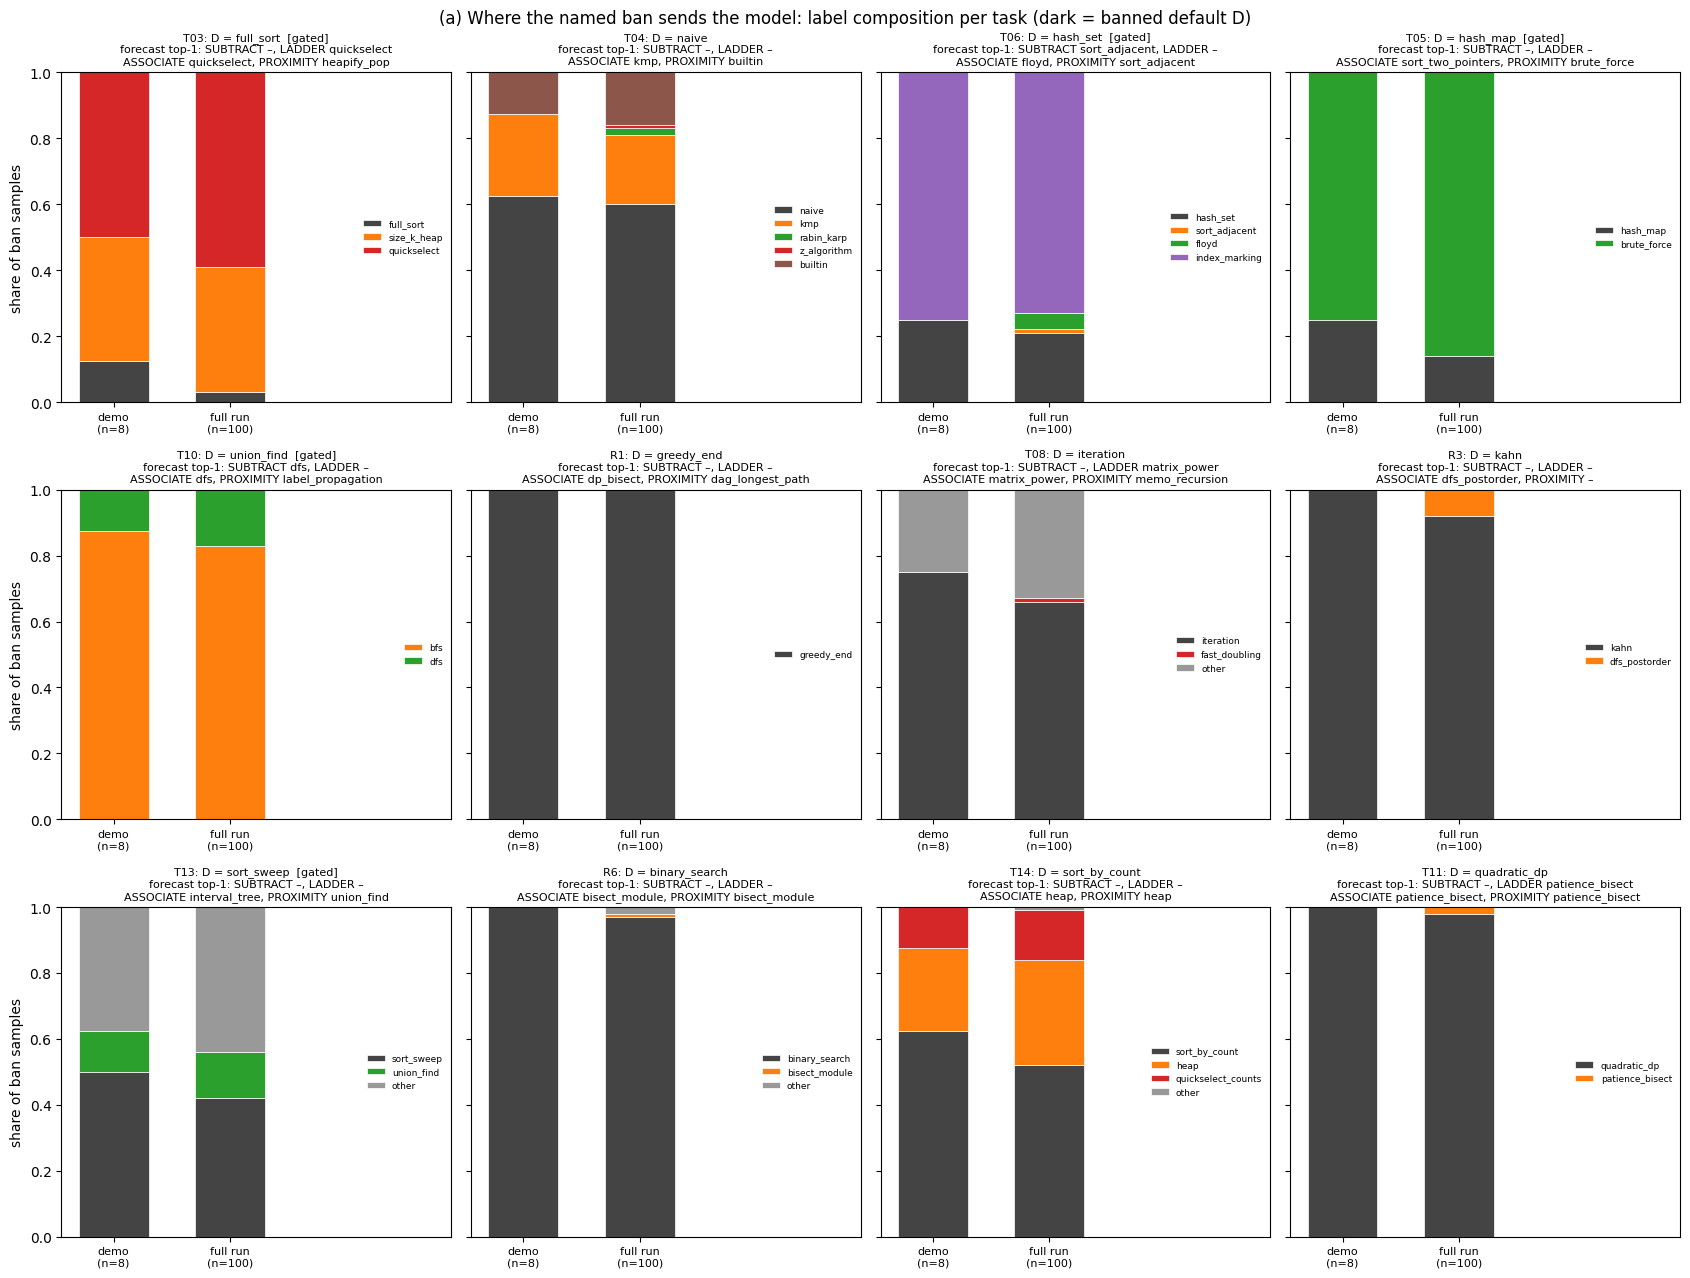

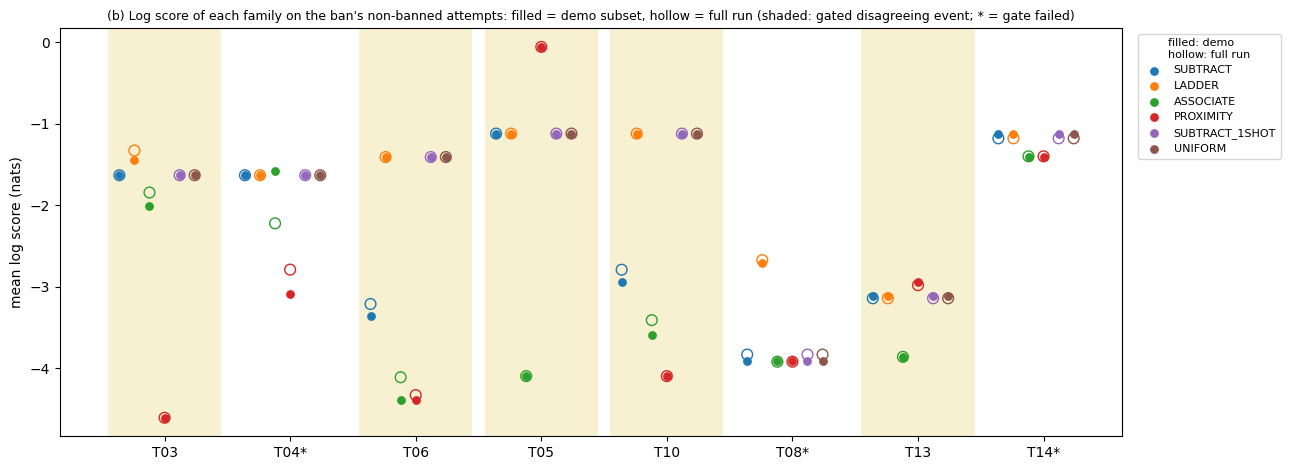

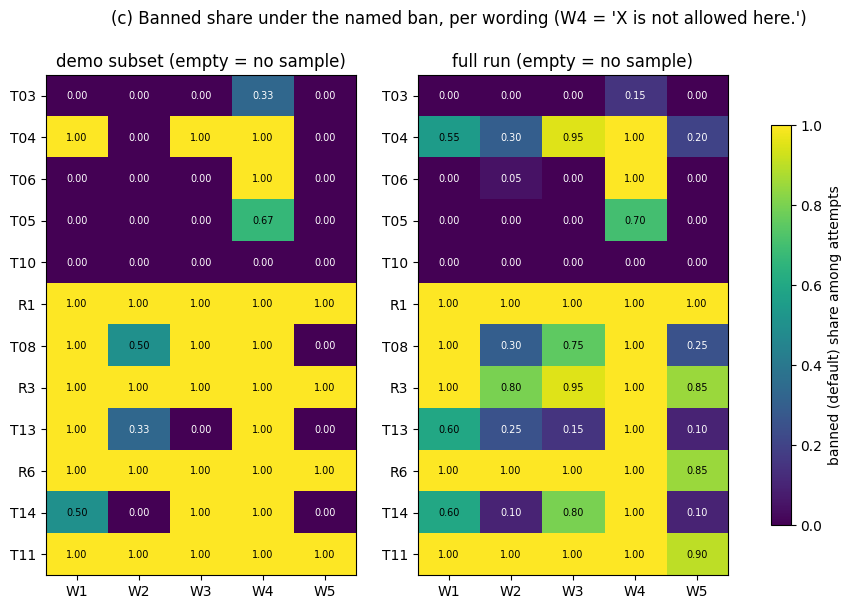

In [22]:
# (a) where each ban landed, demo subset vs full run (after analyze.figures(): composition per task)
fig, axes = plt.subplots(3, 4, figsize=(17, 13), sharey=True)
cmap = plt.get_cmap("tab10")
for ax, t in zip(axes.ravel(), TASK_ORDER):
    D = DEFAULTS[t]
    cats = [D] + survivors(t) + ["other", "invalid"]
    colors = {c: ("#444444" if c == D else "#bbbbbb" if c == "invalid" else "#999999" if c == "other"
                  else cmap(i % 10)) for i, c in enumerate(cats)}
    demo = [r["label"] if r["label"] in cats else "other" for r in arms["ban"] if r["task"] == t]
    ref = REF["c1_events"][t]
    full = Counter(ref["landing_counts"])
    full[D] = ref["n_samples"] - ref["n_non_banned"]  # no ban sample of the full run was invalid
    bottom = np.zeros(2)
    for c in cats:
        vals = np.array([demo.count(c) / len(demo), full.get(c, 0) / ref["n_samples"]])
        if vals.sum() > 0:
            ax.bar([0, 1], vals, bottom=bottom, color=colors[c], label=c, edgecolor="white", linewidth=0.5, width=0.6)
        bottom += vals
    ax.set_xticks([0, 1])
    ax.set_xticklabels([f"demo\n(n={len(demo)})", f"full run\n(n={ref['n_samples']})"], fontsize=8)
    ax.set_xlim(-0.45, 2.9)
    F = fc["tasks"][t]["families"]
    ax.set_title(f"{t}: D = {D}" + ("  [gated]" if ev_by[t]["gate_pass"] else "")
                 + f"\nforecast top-1: SUBTRACT {F['SUBTRACT']['top1'] or '–'}, LADDER {F['LADDER']['top1'] or '–'}"
                 + f"\nASSOCIATE {F['ASSOCIATE']['top1'] or '–'}, PROXIMITY {F['PROXIMITY']['top1'] or '–'}", fontsize=8)
    ax.legend(fontsize=6.5, loc="center right", frameon=False)
axes[0, 0].set_ylabel("share of ban samples")
axes[1, 0].set_ylabel("share of ban samples")
axes[2, 0].set_ylabel("share of ban samples")
fig.suptitle("(a) Where the named ban sends the model: label composition per task (dark = banned default D)")
fig.tight_layout()
plt.show()

# (b) log score of each forecast family per event (after analyze.figures(); shading drawn behind the points)
fams = PRIMARY + ["SUBTRACT_1SHOT", "UNIFORM"]
evp = [e for e in events if e["n_non_banned"] > 0]
fig, ax = plt.subplots(figsize=(13, 4.8))
for i, e in enumerate(evp):
    if e["disagreeing"] and e["gate_pass"]:
        ax.axvspan(i - 0.45, i + 0.45, color="#f3e6b3", alpha=0.6, lw=0, zorder=0)
for j, f in enumerate(fams):
    x = np.arange(len(evp)) + (j - len(fams) / 2) * 0.12
    sc = ax.scatter(x, [e["logscore"][f] for e in evp], label=f, s=28, zorder=3)
    ax.scatter(x, [REF["c1_events"][e["task"]]["logscore"][f] for e in evp], s=60, facecolors="none",
               edgecolors=sc.get_facecolor()[0], linewidths=1.0, zorder=2)
ax.set_xticks(range(len(evp)))
ax.set_xticklabels([e["task"] + ("" if e["gate_pass"] else "*") for e in evp])
ax.set_ylabel("mean log score (nats)")
ax.set_title("(b) Log score of each family on the ban's non-banned attempts: filled = demo subset, hollow = full run "
             "(shaded: gated disagreeing event; * = gate failed)", fontsize=9)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0), title="filled: demo\nhollow: full run",
          title_fontsize=8)
fig.tight_layout()
plt.show()

# (c) banned share per task and wording (after analyze.figures(): template x task heatmap)
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
panels = [("demo subset", {t: {w: v["share"] for w, v in d.items()} for t, d in te["per_template"].items()}),
          ("full run", ref_te["per_template_share"])]
for ax, (title, pt) in zip(axes, panels):
    M = np.full((len(TASK_ORDER), len(WS)), np.nan)
    for i, t in enumerate(TASK_ORDER):
        for j, w in enumerate(WS):
            v = pt.get(t, {}).get(w)
            if v is not None:
                M[i, j] = v
    im = ax.imshow(M, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if not np.isnan(M[i, j]):
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if M[i, j] < 0.5 else "black")
    ax.set_xticks(range(len(WS)))
    ax.set_xticklabels(WS)
    ax.set_yticks(range(len(TASK_ORDER)))
    ax.set_yticklabels(TASK_ORDER)
    ax.set_title(f"{title} (empty = no sample)")
fig.colorbar(im, ax=list(axes), label="banned (default) share among attempts", shrink=0.8)
fig.suptitle("(c) Banned share under the named ban, per wording (W4 = 'X is not allowed here.')")
plt.show()

## What the demo shows

With the shipped configuration (all 96 curated samples, 2,000 bootstrap and null replicates):

- **The subset reproduces the frozen C1 outcome.**
  - The same five bans pass the gate as in the full run: T03, T06, T05, T10 and T13.
  - The committed rule returns the full run's verdict, `SUBTRACTION/LADDER (LADDER)`, with identical wins (LADDER 3, PROXIMITY 2) and the same winner on every event.
- **The verdict rests on undefined forecasts.**
  - Two of LADDER's three wins (T06, T10) come from LADDER being undefined and therefore scored as uniform, while every defined forecast named the wrong algorithm.
  - Counting defined forecasts only gives LADDER 1 and PROXIMITY 2, so no family advances.
- **No family reliably beats a uniform guess.** Mean log score minus uniform over the gated events is about −0.75 for SUBTRACT, +0.04 for LADDER, −1.91 for ASSOCIATE and −1.54 for PROXIMITY. The full run gives −0.69, +0.06, −1.78 and −1.53.
- **Where bans land is mostly unforeseen.**
  - T06 goes to `index_marking`, T10 to `bfs`, and T13 to `other`.
  - Only T03 (`quickselect`) and T05 (`brute_force`) were named by any family's top-1.
- **Token vetoes do not reproduce bans.**
  - The one-shot veto never reaches the 0.5 avoidance that C2b requires, so C2b stays UNDETERMINED.
  - Where the last iterated veto round does move off D, it lands elsewhere: T06 goes to `sort_adjacent` instead of the ban's `index_marking`, and T10 to `dfs` instead of `bfs`.
- **Wording matters.**
  - The template effect is clear even on the 56 informative demo rows (LR ≈ 40, df 4), and the template-shuffled placebo is not significant.
  - In the full run, W4 ("X is not allowed here.") leaves the default in at least 70% of the samples on 10 of the 12 tasks; see heatmap (c).
- **Programs that keep the banned algorithm almost never name it.**

**Caveats.**
- The study covers one model (Qwen3-8B) on memorised, LeetCode-style tasks, and only 5 gated events. C1 is an advance count, not a significance test.
- Here the GPU stages are replaced by their stored, labelled outputs, and every C2b number except the descriptive re-run comes from the stored full-run records.
- The full pipeline runs with `method.py all` in the artifact's repository. It needs Qwen3-8B on a 24 GB GPU and an OpenRouter key for the judge.